In [82]:
import torch
import torch.nn as nn
import joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler
print("AIS Dataset Exploration Started")

AIS Dataset Exploration Started


In [83]:
# Step 51: Restore previously saved project checkpoint

from pathlib import Path
import joblib

# Checkpoint location
checkpoint_path = Path("../data/processed/trajectory_checkpoint.joblib")

# Verify checkpoint exists
if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path.resolve()}"
    )

# Load all saved variables
project_checkpoint = joblib.load(checkpoint_path)

# Restore variables into notebook memory
globals().update(project_checkpoint)

print("PROJECT RESTORED SUCCESSFULLY")
print("--------------------------------")

print("Trajectory data:", trajectory_df.shape)
print("Resampled data:", resampled_df.shape)
print("Model data:", model_df.shape)
print("Valid data:", valid_df.shape)

print("Training sequences:", X_data["Train"].shape)
print("Validation sequences:", X_data["Validation"].shape)
print("Test sequences:", X_data["Test"].shape)

print("Sequence length:", SEQUENCE_LENGTH)
print("Prediction length:", PREDICTION_LENGTH)

print("\nAll saved project variables are ready!")

PROJECT RESTORED SUCCESSFULLY
--------------------------------
Trajectory data: (12107, 8)
Resampled data: (8640, 9)
Model data: (8640, 13)
Valid data: (8603, 14)
Training sequences: (5621, 30, 5)
Validation sequences: (1196, 30, 5)
Test sequences: (1256, 30, 5)
Sequence length: 30
Prediction length: 6

All saved project variables are ready!


In [85]:
# Step 53: Restore evaluation results

evaluation_path = Path("../data/processed/evaluation_results.joblib")

evaluation_results = joblib.load(evaluation_path)

globals().update(evaluation_results)

print("Evaluation results restored!")
print("Constant Velocity ADE:",
      round(cv_raw_original_errors.mean(), 2), "metres")
print("Original AIS target points:", original_mask.sum())

Evaluation results restored!
Constant Velocity ADE: 9.26 metres
Original AIS target points: 2199


In [3]:
DATA_PATH = "../data/aisdk-2025-03-06.csv"

print("Dataset exists:", os.path.exists(DATA_PATH))

if os.path.exists(DATA_PATH):
    print("Dataset size:",
          round(os.path.getsize(DATA_PATH) / (1024**3), 2), "GB")

Dataset exists: True
Dataset size: 4.14 GB


In [4]:
df = pd.read_csv(
    DATA_PATH,
    nrows=10000,
    low_memory=False
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (10000, 26)


,# Timestamp,Type of mobile,MMSI,Latitude,Longitude,Navigational status,ROT,SOG,COG,Heading,...,Length,Type of position fixing device,Draught,Destination,ETA,Data source type,A,B,C,D
0,06/03/2025 00:00:00,Class A,219011867,55.473458,8.423940,Under way using engine,0.0,0.0,244.5,151.0,...,NaN,Undefined,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN
1,06/03/2025 00:00:00,Base Station,2190064,56.716577,11.519050,Unknown value,NaN,NaN,NaN,NaN,...,NaN,GPS,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN
2,06/03/2025 00:00:00,Class A,219000575,55.679138,12.593587,Under way using engine,NaN,0.0,79.6,NaN,...,NaN,Undefined,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN
3,06/03/2025 00:00:00,Class A,219015617,57.494668,10.503758,Engaged in fishing,0.0,0.1,354.7,253.0,...,NaN,Undefined,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN
4,06/03/2025 00:00:00,Class B,219009415,55.058313,15.137552,Unknown value,NaN,0.0,NaN,NaN,...,NaN,Undefined,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['# Timestamp', 'Type of mobile', 'MMSI', 'Latitude', 'Longitude', 'Navigational status', 'ROT', 'SOG', 'COG', 'Heading', 'IMO', 'Callsign', 'Name', 'Ship type', 'Cargo type', 'Width', 'Length', 'Type of position fixing device', 'Draught', 'Destination', 'ETA', 'Data source type', 'A', 'B', 'C', 'D']

Data types:
# Timestamp                           str
Type of mobile                        str
MMSI                                int64
Latitude                          float64
Longitude                         float64
Navigational status                   str
ROT                               float64
SOG                               float64
COG                               float64
Heading                           float64
IMO                                   str
Callsign                              str
Name                                  str
Ship type                             str
Cargo type                            str
Width                             float64

In [6]:
pd.set_option("display.max_columns", None)

print("Total columns:", len(df.columns))
display(df.head(5))

Total columns: 26


,# Timestamp,Type of mobile,MMSI,Latitude,Longitude,Navigational status,ROT,SOG,COG,Heading,IMO,Callsign,Name,Ship type,Cargo type,Width,Length,Type of position fixing device,Draught,Destination,ETA,Data source type,A,B,C,D
0,06/03/2025 00:00:00,Class A,219011867,55.473458,8.423940,Under way using engine,0.0,0.0,244.5,151.0,Unknown,Unknown,NaN,Undefined,NaN,NaN,NaN,Undefined,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN
1,06/03/2025 00:00:00,Base Station,2190064,56.716577,11.519050,Unknown value,NaN,NaN,NaN,NaN,Unknown,Unknown,NaN,Undefined,NaN,NaN,NaN,GPS,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN
2,06/03/2025 00:00:00,Class A,219000575,55.679138,12.593587,Under way using engine,NaN,0.0,79.6,NaN,Unknown,Unknown,NaN,Undefined,NaN,NaN,NaN,Undefined,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN
3,06/03/2025 00:00:00,Class A,219015617,57.494668,10.503758,Engaged in fishing,0.0,0.1,354.7,253.0,Unknown,Unknown,NaN,Undefined,NaN,NaN,NaN,Undefined,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN
4,06/03/2025 00:00:00,Class B,219009415,55.058313,15.137552,Unknown value,NaN,0.0,NaN,NaN,Unknown,Unknown,NaN,Undefined,NaN,NaN,NaN,Undefined,NaN,Unknown,NaN,AIS,NaN,NaN,NaN,NaN


In [7]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df)
    ) * 100
})

display(missing.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Values,Missing Percentage
Cargo type,9902,99.02
ETA,9552,95.52
Draught,9450,94.50
C,9145,91.45
A,9135,91.35
B,9133,91.33
Length,9131,91.31
D,9131,91.31
Width,9128,91.28
Name,9022,90.22


In [8]:
print(df["# Timestamp"].head(10))

print("\nTimestamp data type:")
print(df["# Timestamp"].dtype)

0    06/03/2025 00:00:00
1    06/03/2025 00:00:00
2    06/03/2025 00:00:00
3    06/03/2025 00:00:00
4    06/03/2025 00:00:00
5    06/03/2025 00:00:00
6    06/03/2025 00:00:00
7    06/03/2025 00:00:00
8    06/03/2025 00:00:00
9    06/03/2025 00:00:00
Name: # Timestamp, dtype: str

Timestamp data type:
str


In [9]:
print("Unique vessels:", df["MMSI"].nunique())

print("\nTop 10 vessels by observation count:")

print(
    df["MMSI"]
    .value_counts()
    .head(10)
)

Unique vessels: 1506

Top 10 vessels by observation count:
MMSI
219024676    57
538011342    47
244130873    47
2190068      43
266331000    41
231023000    41
352004897    39
210510000    37
2655135      37
211190000    37
Name: count, dtype: int64


In [10]:
import pandas as pd
from collections import Counter

DATA_PATH = "../data/aisdk-2025-03-06.csv"

vessel_counts = Counter()
total_records = 0

for chunk in pd.read_csv(
    DATA_PATH,
    chunksize=100_000,
    low_memory=False
):
    vessel_counts.update(chunk["MMSI"].dropna())
    total_records += len(chunk)

print("Total AIS records:", total_records)
print("Total unique vessels:", len(vessel_counts))

print("\nTop 10 vessels:")
print(vessel_counts.most_common(10))

Total AIS records: 24168735
Total unique vessels: 4548

Top 10 vessels:
[(2190049, 82065), (2190068, 75301), (2190051, 73141), (352001823, 71703), (2655135, 70463), (2190076, 66755), (2190048, 65599), (2190069, 64837), (235002520, 63083), (636019341, 61932)]


In [11]:
import pandas as pd

DATA_PATH = "../data/aisdk-2025-03-06.csv"

target_mmsi = 2190049
vessel_records = []

required_columns = [
    "# Timestamp",
    "MMSI",
    "Latitude",
    "Longitude",
    "SOG",
    "COG",
    "ROT"
]

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=required_columns,
    chunksize=100_000,
    low_memory=False
):
    vessel_data = chunk[chunk["MMSI"] == target_mmsi]

    if not vessel_data.empty:
        vessel_records.append(vessel_data)

vessel_df = pd.concat(vessel_records, ignore_index=True)

vessel_df["# Timestamp"] = pd.to_datetime(
    vessel_df["# Timestamp"],
    dayfirst=True,
    errors="coerce"
)

vessel_df = vessel_df.sort_values("# Timestamp").reset_index(drop=True)

print("Vessel MMSI:", target_mmsi)
print("Total records:", len(vessel_df))

print("\nFirst 5 records:")
display(vessel_df.head())

print("\nLast 5 records:")
display(vessel_df.tail())

print("\nTime coverage:")
print("Start:", vessel_df["# Timestamp"].min())
print("End:", vessel_df["# Timestamp"].max())

print("\nMissing values:")
print(vessel_df.isnull().sum())

Vessel MMSI: 2190049
Total records: 82065

First 5 records:


,# Timestamp,MMSI,Latitude,Longitude,ROT,SOG,COG
0,2025-03-06 00:00:04,2190049,55.735817,10.918782,NaN,NaN,NaN
1,2025-03-06 00:00:05,2190049,55.735817,10.918782,NaN,NaN,NaN
2,2025-03-06 00:00:05,2190049,55.735817,10.918782,NaN,NaN,NaN
3,2025-03-06 00:00:05,2190049,55.735817,10.918782,NaN,NaN,NaN
4,2025-03-06 00:00:05,2190049,55.735817,10.918782,NaN,NaN,NaN



Last 5 records:


,# Timestamp,MMSI,Latitude,Longitude,ROT,SOG,COG
82060,2025-03-06 23:59:55,2190049,55.735817,10.918782,NaN,NaN,NaN
82061,2025-03-06 23:59:55,2190049,55.735817,10.918782,NaN,NaN,NaN
82062,2025-03-06 23:59:55,2190049,55.735817,10.918782,NaN,NaN,NaN
82063,2025-03-06 23:59:55,2190049,55.735817,10.918782,NaN,NaN,NaN
82064,2025-03-06 23:59:55,2190049,55.735817,10.918782,NaN,NaN,NaN



Time coverage:
Start: 2025-03-06 00:00:04
End: 2025-03-06 23:59:55

Missing values:
# Timestamp        0
MMSI               0
Latitude           0
Longitude          0
ROT            82065
SOG            82065
COG            82065
dtype: int64


In [12]:
time_gaps = vessel_df["# Timestamp"].diff().dt.total_seconds()

print("Average time gap (seconds):", time_gaps.mean())
print("Median time gap (seconds):", time_gaps.median())
print("Maximum time gap (seconds):", time_gaps.max())

print("\nTime gap distribution:")
print(time_gaps.describe())

Average time gap (seconds): 1.052727139793332
Median time gap (seconds): 0.0
Maximum time gap (seconds): 19.0

Time gap distribution:
count    82064.000000
mean         1.052727
std          2.751128
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         19.000000
Name: # Timestamp, dtype: float64


In [13]:
# Check whether the vessel has different positions
print("Unique latitudes:", vessel_df["Latitude"].nunique())
print("Unique longitudes:", vessel_df["Longitude"].nunique())

print(
    "Unique coordinate pairs:",
    vessel_df[["Latitude", "Longitude"]].drop_duplicates().shape[0]
)

# Check exact duplicate records
print(
    "Exact duplicate rows:",
    vessel_df.duplicated().sum()
)

# Check how many distinct timestamps exist
print(
    "Unique timestamps:",
    vessel_df["# Timestamp"].nunique()
)

# Check the most frequently repeated timestamps
print("\nMost repeated timestamps:")
print(
    vessel_df["# Timestamp"]
    .value_counts()
    .head(10)
)

# Show the most frequently reported positions
print("\nMost frequently reported positions:")
print(
    vessel_df.groupby(["Latitude", "Longitude"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Unique latitudes: 1
Unique longitudes: 1
Unique coordinate pairs: 1
Exact duplicate rows: 64971
Unique timestamps: 17094

Most repeated timestamps:
# Timestamp
2025-03-06 22:44:55    18
2025-03-06 20:58:35    17
2025-03-06 21:00:15    17
2025-03-06 22:15:15    17
2025-03-06 22:20:55    17
2025-03-06 22:30:55    17
2025-03-06 22:31:35    17
2025-03-06 22:31:55    17
2025-03-06 22:32:35    17
2025-03-06 22:33:55    17
Name: count, dtype: int64

Most frequently reported positions:
Latitude   Longitude
55.735817  10.918782    82065
dtype: int64


In [14]:
import pandas as pd

DATA_PATH = "../data/aisdk-2025-03-06.csv"

vessel_stats = {}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["MMSI", "Latitude", "Longitude", "SOG", "COG"],
    chunksize=100_000,
    low_memory=False
):
    # Keep valid geographic coordinates
    valid = chunk[
        chunk["Latitude"].between(-90, 90)
        & chunk["Longitude"].between(-180, 180)
    ].copy()

    # Count records with valid movement information
    valid_motion = valid.dropna(subset=["SOG", "COG"])

    for mmsi, group in valid.groupby("MMSI"):
        if pd.isna(mmsi):
            continue

        stats = vessel_stats.setdefault(
            mmsi,
            {
                "valid_records": 0,
                "motion_records": 0,
                "min_lat": float("inf"),
                "max_lat": float("-inf"),
                "min_lon": float("inf"),
                "max_lon": float("-inf")
            }
        )

        stats["valid_records"] += len(group)
        stats["motion_records"] += int(
            (valid_motion["MMSI"] == mmsi).sum()
        )

        stats["min_lat"] = min(
            stats["min_lat"], group["Latitude"].min()
        )
        stats["max_lat"] = max(
            stats["max_lat"], group["Latitude"].max()
        )
        stats["min_lon"] = min(
            stats["min_lon"], group["Longitude"].min()
        )
        stats["max_lon"] = max(
            stats["max_lon"], group["Longitude"].max()
        )

# Convert results into a DataFrame
results = []

for mmsi, stats in vessel_stats.items():
    results.append({
        "MMSI": mmsi,
        "Valid Records": stats["valid_records"],
        "Motion Records": stats["motion_records"],
        "Latitude Range": stats["max_lat"] - stats["min_lat"],
        "Longitude Range": stats["max_lon"] - stats["min_lon"]
    })

vessel_summary = pd.DataFrame(results)

# Keep vessels with movement and sufficient motion records
candidates = vessel_summary[
    (vessel_summary["Motion Records"] >= 1000)
    & (
        (vessel_summary["Latitude Range"] > 0)
        | (vessel_summary["Longitude Range"] > 0)
    )
].sort_values("Motion Records", ascending=False)

print("Suitable vessel candidates:", len(candidates))
display(candidates.head(15))

Suitable vessel candidates: 1845


,MMSI,Valid Records,Motion Records,Latitude Range,Longitude Range
2068,352001823,71698,71698,1.817086,3.326589
1456,235002520,63083,63083,2.766677,5.086788
3133,636019341,61932,61932,3.949608,6.522190
1934,265859000,61835,61835,0.244333,1.924166
87,210090000,61057,61057,3.049847,1.174245
1475,236112746,59457,59442,57.723093,107.728318
1536,244850612,58894,58890,3.022439,4.586261
1732,257339000,58650,58650,0.309797,0.276958
130,211190000,58243,58243,14.072264,27.211235
920,219022903,58221,58221,0.194107,1.046965


In [15]:
import pandas as pd

DATA_PATH = "../data/aisdk-2025-03-06.csv"

target_mmsi = 352001823
vessel_records = []

required_columns = [
    "# Timestamp",
    "MMSI",
    "Latitude",
    "Longitude",
    "SOG",
    "COG",
    "ROT"
]

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=required_columns,
    chunksize=100_000,
    low_memory=False
):
    vessel_data = chunk[chunk["MMSI"] == target_mmsi]

    if not vessel_data.empty:
        vessel_records.append(vessel_data)

vessel_df = pd.concat(vessel_records, ignore_index=True)

# Parse timestamps
vessel_df["# Timestamp"] = pd.to_datetime(
    vessel_df["# Timestamp"],
    dayfirst=True,
    errors="coerce"
)

# Sort chronologically
vessel_df = vessel_df.sort_values("# Timestamp").reset_index(drop=True)

print("MMSI:", target_mmsi)
print("Total records:", len(vessel_df))

print("\nFirst 5 records:")
display(vessel_df.head())

print("\nLast 5 records:")
display(vessel_df.tail())

MMSI: 352001823
Total records: 71703

First 5 records:


,# Timestamp,MMSI,Latitude,Longitude,ROT,SOG,COG
0,2025-03-06 00:00:04,352001823,91.0,0.0,NaN,NaN,NaN
1,2025-03-06 00:00:04,352001823,91.0,0.0,NaN,NaN,NaN
2,2025-03-06 00:00:04,352001823,91.0,0.0,NaN,NaN,NaN
3,2025-03-06 00:00:04,352001823,91.0,0.0,NaN,NaN,NaN
4,2025-03-06 00:00:04,352001823,91.0,0.0,NaN,NaN,NaN



Last 5 records:


,# Timestamp,MMSI,Latitude,Longitude,ROT,SOG,COG
71698,2025-03-06 23:59:58,352001823,56.259533,11.365912,NaN,11.4,29.9
71699,2025-03-06 23:59:58,352001823,56.259533,11.365912,NaN,11.4,29.9
71700,2025-03-06 23:59:58,352001823,56.259533,11.365912,NaN,11.4,29.9
71701,2025-03-06 23:59:58,352001823,56.259533,11.365912,NaN,11.4,29.9
71702,2025-03-06 23:59:58,352001823,56.259533,11.365912,NaN,11.4,29.9


In [16]:
print("Unique latitude values:", vessel_df["Latitude"].nunique())
print("Unique longitude values:", vessel_df["Longitude"].nunique())

print(
    "Unique coordinate pairs:",
    vessel_df[["Latitude", "Longitude"]].drop_duplicates().shape[0]
)

print("\nMissing values:")
print(vessel_df.isnull().sum())

print("\nExact duplicate rows:")
print(vessel_df.duplicated().sum())

print("\nTime coverage:")
print("Start:", vessel_df["# Timestamp"].min())
print("End:", vessel_df["# Timestamp"].max())

print("\nMovement statistics:")
print(vessel_df[["SOG", "COG", "ROT"]].describe())

Unique latitude values: 11483
Unique longitude values: 11264
Unique coordinate pairs: 11701

Missing values:
# Timestamp        0
MMSI               0
Latitude           0
Longitude          0
ROT            71703
SOG                5
COG                5
dtype: int64

Exact duplicate rows:
59570

Time coverage:
Start: 2025-03-06 00:00:04
End: 2025-03-06 23:59:58

Movement statistics:
                SOG           COG  ROT
count  71698.000000  71698.000000  0.0
mean      10.130602    153.103007  NaN
std        0.976771    135.970392  NaN
min        3.600000      0.000000  NaN
25%        9.600000     23.400000  NaN
50%       10.300000     71.900000  NaN
75%       10.800000    275.100000  NaN
max       11.500000    359.900000  NaN


In [17]:
# Create a copy of the original vessel data
clean_df = vessel_df.copy()

# Step 1: Remove invalid geographic coordinates
clean_df = clean_df[
    clean_df["Latitude"].between(-90, 90)
    & clean_df["Longitude"].between(-180, 180)
].copy()

print("After removing invalid coordinates:", len(clean_df))

# Step 2: Remove exact duplicate records
clean_df = clean_df.drop_duplicates().copy()

print("After removing exact duplicates:", len(clean_df))

# Step 3: Remove records without valid position or movement data
clean_df = clean_df.dropna(
    subset=["# Timestamp", "Latitude", "Longitude", "SOG", "COG"]
).copy()

# Step 4: Sort records chronologically
clean_df = clean_df.sort_values("# Timestamp").reset_index(drop=True)

print("\nFinal cleaned records:", len(clean_df))

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nFirst 5 cleaned records:")
display(clean_df.head())

print("\nLast 5 cleaned records:")
display(clean_df.tail())

After removing invalid coordinates: 71698
After removing exact duplicates: 12132

Final cleaned records: 12132

Missing values:
# Timestamp        0
MMSI               0
Latitude           0
Longitude          0
ROT            12132
SOG                0
COG                0
dtype: int64

First 5 cleaned records:


,# Timestamp,MMSI,Latitude,Longitude,ROT,SOG,COG
0,2025-03-06 00:00:08,352001823,55.087370,14.106402,NaN,10.5,219.5
1,2025-03-06 00:00:18,352001823,55.086997,14.105868,NaN,10.5,219.5
2,2025-03-06 00:00:28,352001823,55.086625,14.105332,NaN,10.4,220.0
3,2025-03-06 00:00:38,352001823,55.086253,14.104795,NaN,10.4,219.8
4,2025-03-06 00:00:47,352001823,55.085957,14.104363,NaN,10.4,220.3



Last 5 cleaned records:


,# Timestamp,MMSI,Latitude,Longitude,ROT,SOG,COG
12127,2025-03-06 23:59:18,352001823,56.257712,11.364045,NaN,11.4,29.6
12128,2025-03-06 23:59:28,352001823,56.258167,11.364512,NaN,11.4,29.8
12129,2025-03-06 23:59:38,352001823,56.258622,11.364978,NaN,11.4,29.7
12130,2025-03-06 23:59:48,352001823,56.259078,11.365445,NaN,11.3,29.8
12131,2025-03-06 23:59:58,352001823,56.259533,11.365912,NaN,11.4,29.9


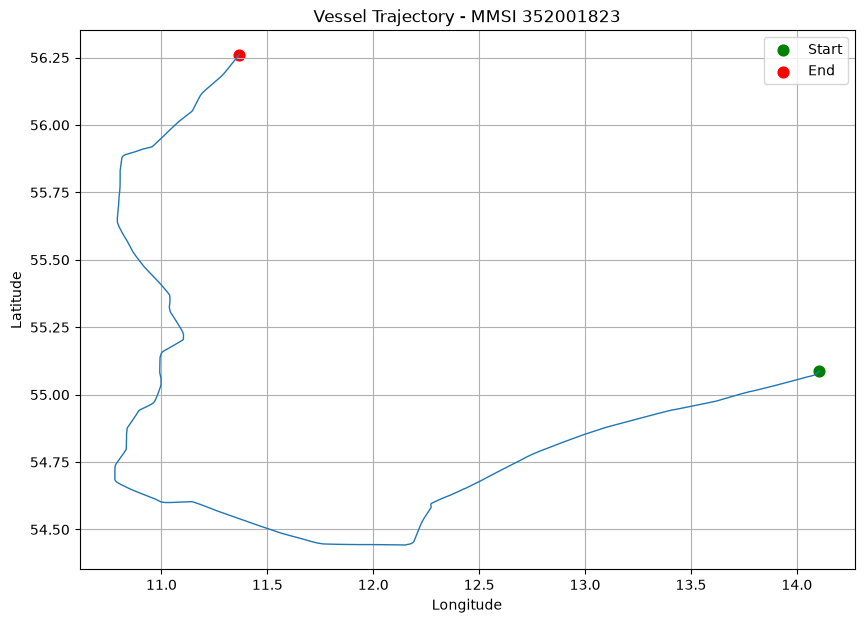

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.plot(
    clean_df["Longitude"],
    clean_df["Latitude"],
    linewidth=1
)

plt.scatter(
    clean_df["Longitude"].iloc[0],
    clean_df["Latitude"].iloc[0],
    color="green",
    label="Start",
    s=60
)

plt.scatter(
    clean_df["Longitude"].iloc[-1],
    clean_df["Latitude"].iloc[-1],
    color="red",
    label="End",
    s=60
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Vessel Trajectory - MMSI 352001823")
plt.legend()
plt.grid(True)

plt.show()

In [19]:
import numpy as np
import pandas as pd

# Calculate time difference between consecutive records
clean_df["Time_Gap"] = (
    clean_df["# Timestamp"].diff().dt.total_seconds()
)

# Calculate latitude and longitude differences in radians
lat1 = np.radians(clean_df["Latitude"].shift(1))
lat2 = np.radians(clean_df["Latitude"])

lon1 = np.radians(clean_df["Longitude"].shift(1))
lon2 = np.radians(clean_df["Longitude"])

# Haversine distance calculation
dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

clean_df["Distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a))
)

# Calculate speed from consecutive positions
clean_df["Calculated_SOG"] = (
    clean_df["Distance_km"]
    / clean_df["Time_Gap"]
    * 3600 / 1.852
)

# First row and non-positive time gaps cannot produce a valid speed
clean_df.loc[
    clean_df["Time_Gap"] <= 0,
    "Calculated_SOG"
] = np.nan

print("TIME GAP STATISTICS (seconds)")
print(clean_df["Time_Gap"].describe())

print("\nCALCULATED SPEED STATISTICS (knots)")
print(clean_df["Calculated_SOG"].describe())

print("\nREPORTED SOG STATISTICS (knots)")
print(clean_df["SOG"].describe())

TIME GAP STATISTICS (seconds)
count    12131.000000
mean         7.121424
std          4.015737
min          0.000000
25%          2.000000
50%          9.000000
75%         10.000000
max         30.000000
Name: Time_Gap, dtype: float64

CALCULATED SPEED STATISTICS (knots)
count    12106.000000
mean        10.432756
std          6.155689
min          0.000000
25%          9.511160
50%         10.309549
75%         10.961851
max        124.752220
Name: Calculated_SOG, dtype: float64

REPORTED SOG STATISTICS (knots)
count    12132.000000
mean        10.153882
std          1.061683
min          3.600000
25%          9.700000
50%         10.400000
75%         10.900000
max         11.500000
Name: SOG, dtype: float64


In [20]:
# Identify records with calculated speed above 30 knots
unusual = clean_df[
    clean_df["Calculated_SOG"] > 30
]

print("Records with calculated speed > 30 knots:", len(unusual))

display(
    unusual[
        [
            "# Timestamp",
            "Latitude",
            "Longitude",
            "SOG",
            "Calculated_SOG",
            "Time_Gap"
        ]
    ].head(10)
)

Records with calculated speed > 30 knots: 102


,# Timestamp,Latitude,Longitude,SOG,Calculated_SOG,Time_Gap
148,2025-03-06 00:24:08,55.056035,14.003538,10.5,31.423212,3.0
373,2025-03-06 01:00:07,55.020232,13.829722,10.8,48.510650,2.0
658,2025-03-06 01:18:07,55.003442,13.739380,11.0,54.944728,2.0
731,2025-03-06 01:30:05,54.989745,13.679420,11.3,89.690989,1.0
806,2025-03-06 01:42:07,54.975870,13.618707,11.4,62.106050,2.0
844,2025-03-06 01:48:07,54.970700,13.587140,11.3,30.921090,4.0
881,2025-03-06 01:54:06,54.965683,13.555838,11.3,37.354994,3.0
918,2025-03-06 02:00:06,54.960603,13.524718,11.2,111.234246,1.0
992,2025-03-06 02:12:05,54.950700,13.463140,11.1,99.266248,1.0
1028,2025-03-06 02:18:06,54.945943,13.432093,11.1,33.235903,3.0


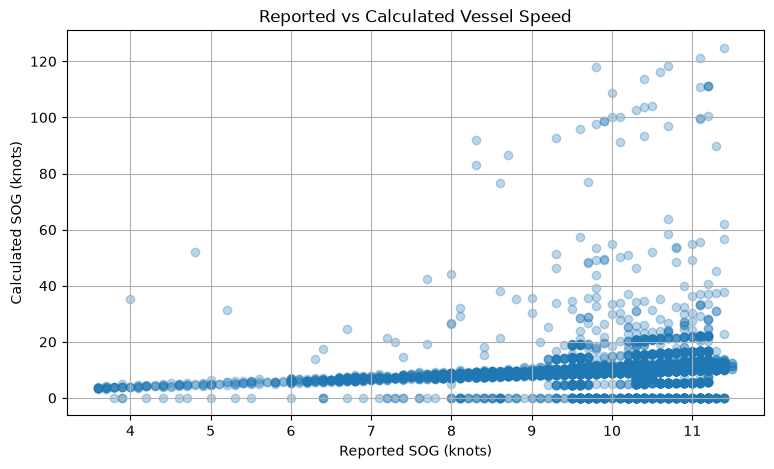

In [21]:
comparison = clean_df.dropna(
    subset=["Calculated_SOG", "SOG"]
).copy()

plt.figure(figsize=(9, 5))

plt.scatter(
    comparison["SOG"],
    comparison["Calculated_SOG"],
    alpha=0.3
)

plt.xlabel("Reported SOG (knots)")
plt.ylabel("Calculated SOG (knots)")
plt.title("Reported vs Calculated Vessel Speed")
plt.grid(True)

plt.show()

In [22]:
# Add previous position and timestamp for comparison
clean_df["Previous_Timestamp"] = clean_df["# Timestamp"].shift(1)
clean_df["Previous_Latitude"] = clean_df["Latitude"].shift(1)
clean_df["Previous_Longitude"] = clean_df["Longitude"].shift(1)

# Select suspicious movement records
outliers = clean_df[
    clean_df["Calculated_SOG"] > 30
].copy()

# Display the most extreme cases
outliers = outliers.sort_values(
    "Calculated_SOG",
    ascending=False
)

columns_to_show = [
    "Previous_Timestamp",
    "# Timestamp",
    "Previous_Latitude",
    "Previous_Longitude",
    "Latitude",
    "Longitude",
    "Time_Gap",
    "SOG",
    "Calculated_SOG"
]

display(outliers[columns_to_show].head(20))

,Previous_Timestamp,# Timestamp,Previous_Latitude,Previous_Longitude,Latitude,Longitude,Time_Gap,SOG,Calculated_SOG
1730,2025-03-06 04:12:05,2025-03-06 04:12:06,54.814545,12.866523,54.814260,12.865652,1.0,11.4,124.752220
5859,2025-03-06 12:30:05,2025-03-06 12:30:06,54.652797,10.845153,54.653105,10.844342,1.0,11.1,121.311327
5927,2025-03-06 12:42:05,2025-03-06 12:42:06,54.673742,10.793042,54.674072,10.792288,1.0,10.7,118.186966
6811,2025-03-06 15:06:05,2025-03-06 15:06:06,55.016987,10.989932,55.017512,10.990188,1.0,9.8,117.827561
2605,2025-03-06 05:42:04,2025-03-06 05:42:05,54.665713,12.469697,54.665395,12.468947,1.0,10.6,116.251946
3229,2025-03-06 07:24:04,2025-03-06 07:24:05,54.515580,12.222755,54.515080,12.222477,1.0,10.4,113.562241
1470,2025-03-06 03:30:05,2025-03-06 03:30:06,54.871422,13.069490,54.871232,13.068658,1.0,11.2,111.330060
918,2025-03-06 02:00:05,2025-03-06 02:00:06,54.960740,13.525582,54.960603,13.524718,1.0,11.2,111.234246
1507,2025-03-06 03:36:05,2025-03-06 03:36:06,54.863952,13.040080,54.863748,13.039260,1.0,11.2,111.127361
3337,2025-03-06 07:42:03,2025-03-06 07:42:04,54.464470,12.197158,54.463975,12.196930,1.0,11.1,110.759730


In [23]:
print("Zero time gaps:", (clean_df["Time_Gap"] == 0).sum())

print("Negative time gaps:", (clean_df["Time_Gap"] < 0).sum())

print(
    "Positive time gaps:",
    (clean_df["Time_Gap"] > 0).sum()
)

print("\nTime gap frequency:")
print(clean_df["Time_Gap"].value_counts().sort_index().head(15))

Zero time gaps: 25
Negative time gaps: 0
Positive time gaps: 12106

Time gap frequency:
Time_Gap
0.0       25
1.0      456
2.0     3626
3.0      141
4.0       58
5.0       53
6.0       51
7.0       55
8.0      322
9.0     1918
10.0    3299
11.0    1822
12.0     239
16.0       1
18.0       1
Name: count, dtype: int64


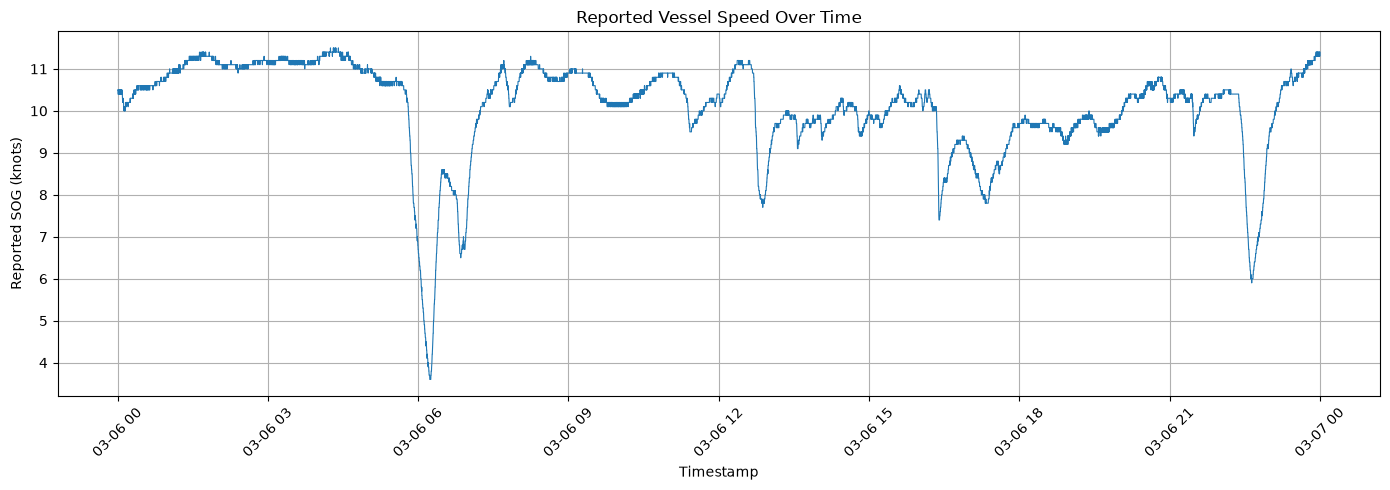

In [24]:
import matplotlib.pyplot as plt

# Plot reported SOG over time
plt.figure(figsize=(14, 5))

plt.plot(
    clean_df["# Timestamp"],
    clean_df["SOG"],
    linewidth=0.8
)

plt.xlabel("Timestamp")
plt.ylabel("Reported SOG (knots)")
plt.title("Reported Vessel Speed Over Time")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

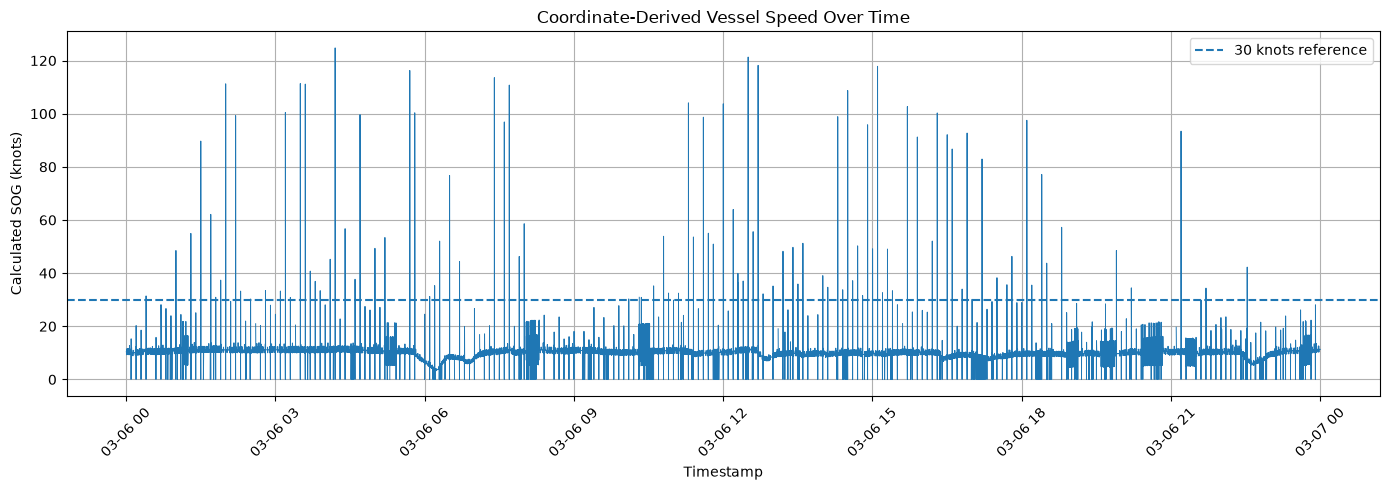

In [25]:
plt.figure(figsize=(14, 5))

plt.plot(
    clean_df["# Timestamp"],
    clean_df["Calculated_SOG"],
    linewidth=0.7
)

plt.axhline(
    y=30,
    linestyle="--",
    label="30 knots reference"
)

plt.xlabel("Timestamp")
plt.ylabel("Calculated SOG (knots)")
plt.title("Coordinate-Derived Vessel Speed Over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
# Count records per timestamp
timestamp_counts = (
    clean_df.groupby("# Timestamp")
    .size()
    .sort_values(ascending=False)
)

print("Total unique timestamps:", len(timestamp_counts))

print("\nTimestamps with multiple records:")
print(timestamp_counts[timestamp_counts > 1].head(15))

print(
    "\nNumber of timestamps with multiple records:",
    (timestamp_counts > 1).sum()
)

Total unique timestamps: 12107

Timestamps with multiple records:
# Timestamp
2025-03-06 10:30:05    2
2025-03-06 10:18:48    2
2025-03-06 08:18:03    2
2025-03-06 05:18:02    2
2025-03-06 01:14:46    2
2025-03-06 06:36:04    2
2025-03-06 02:36:05    2
2025-03-06 07:06:04    2
2025-03-06 10:30:36    2
2025-03-06 03:24:05    2
2025-03-06 13:06:05    2
2025-03-06 15:36:05    2
2025-03-06 18:18:05    2
2025-03-06 18:55:06    2
2025-03-06 18:55:16    2
dtype: int64

Number of timestamps with multiple records: 25


In [27]:
# Check whether the same timestamp contains different positions
position_variation = (
    clean_df.groupby("# Timestamp")
    .agg(
        unique_positions=(
            "Latitude",
            lambda x: len(
                clean_df.loc[x.index, ["Latitude", "Longitude"]]
                .drop_duplicates()
            )
        ),
        records=("MMSI", "size")
    )
)

print("Timestamps containing multiple different positions:")
display(
    position_variation[
        position_variation["unique_positions"] > 1
    ].head(15)
)

print(
    "\nTotal timestamps with different positions:",
    (position_variation["unique_positions"] > 1).sum()
)

Timestamps containing multiple different positions:


,unique_positions,records
# Timestamp,,
2025-03-06 01:14:46,2,2
2025-03-06 02:36:05,2,2
2025-03-06 03:24:05,2,2
2025-03-06 05:18:02,2,2
2025-03-06 06:36:04,2,2
2025-03-06 07:06:04,2,2
2025-03-06 08:18:03,2,2
2025-03-06 10:18:48,2,2
2025-03-06 10:30:05,2,2



Total timestamps with different positions: 25


In [28]:
# Find timestamps that have multiple different positions
conflict_times = position_variation[
    position_variation["unique_positions"] > 1
].index

# Extract all records associated with those timestamps
conflict_records = clean_df[
    clean_df["# Timestamp"].isin(conflict_times)
].copy()

# Display relevant columns
conflict_records = conflict_records.sort_values(
    "# Timestamp"
)

display(
    conflict_records[
        [
            "# Timestamp",
            "Latitude",
            "Longitude",
            "SOG",
            "COG"
        ]
    ].to_string(index=False)
)

'        # Timestamp  Latitude  Longitude  SOG   COG\n2025-03-06 01:14:46 55.007020  13.756045 11.0 249.4\n2025-03-06 01:14:46 55.007002  13.755962 11.0 249.4\n2025-03-06 02:36:05 54.929462  13.340893 11.1 248.4\n2025-03-06 02:36:05 54.929630  13.341637 11.1 248.6\n2025-03-06 03:24:05 54.878440  13.098450 11.2 248.0\n2025-03-06 03:24:05 54.878633  13.099282 11.2 247.9\n2025-03-06 05:18:02 54.706215  12.569722 10.7 233.1\n2025-03-06 05:18:02 54.706155  12.569585 10.7 232.9\n2025-03-06 06:36:04 54.610865  12.312692  8.4 237.8\n2025-03-06 06:36:04 54.610658  12.312125  8.4 238.1\n2025-03-06 07:06:04 54.560958  12.255692  9.3 206.6\n2025-03-06 07:06:04 54.561303  12.255988  9.3 206.4\n2025-03-06 08:18:03 54.443740  12.030607 11.2 270.9\n2025-03-06 08:18:03 54.443742  12.030430 11.2 271.1\n2025-03-06 10:18:48 54.518515  11.444513 10.4 295.7\n2025-03-06 10:18:48 54.518473  11.444662 10.3 295.7\n2025-03-06 10:30:05 54.532495  11.394148 10.5 295.2\n2025-03-06 10:30:05 54.532475  11.394223 10.5

In [29]:
from math import radians, sin, cos, asin, sqrt

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2)
        * sin(dlon / 2) ** 2
    )

    return 6371 * 2 * asin(sqrt(a))


conflict_distances = []

for timestamp, group in conflict_records.groupby("# Timestamp"):
    first = group.iloc[0]
    second = group.iloc[1]

    distance = haversine_distance(
        first["Latitude"],
        first["Longitude"],
        second["Latitude"],
        second["Longitude"]
    )

    conflict_distances.append({
        "Timestamp": timestamp,
        "Distance_km": distance,
        "First_SOG": first["SOG"],
        "Second_SOG": second["SOG"],
        "First_COG": first["COG"],
        "Second_COG": second["COG"]
    })

conflict_distance_df = pd.DataFrame(conflict_distances)

display(
    conflict_distance_df.sort_values(
        "Distance_km",
        ascending=False
    )
)

,Timestamp,Distance_km,First_SOG,Second_SOG,First_COG,Second_COG
11,2025-03-06 15:36:05,0.059507,10.5,10.5,1.5,1.8
22,2025-03-06 21:06:03,0.058337,10.3,10.3,67.7,67.7
2,2025-03-06 03:24:05,0.057388,11.2,11.2,248.0,247.9
12,2025-03-06 18:18:05,0.054515,9.7,9.7,324.4,324.4
1,2025-03-06 02:36:05,0.051074,11.1,11.1,248.4,248.6
10,2025-03-06 13:06:05,0.048922,9.6,9.5,5.7,5.6
4,2025-03-06 06:36:04,0.043162,8.4,8.4,237.8,238.1
5,2025-03-06 07:06:04,0.042847,9.3,9.3,206.6,206.4
19,2025-03-06 19:40:57,0.014601,9.6,9.5,4.3,4.2
6,2025-03-06 08:18:03,0.011447,11.2,11.2,270.9,271.1


In [30]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))


consistency_results = []

for timestamp in conflict_times:

    # Two conflicting positions
    group = clean_df[
        clean_df["# Timestamp"] == timestamp
    ].sort_values(["Latitude", "Longitude"])

    # Previous and next timestamp
    previous = clean_df[
        clean_df["# Timestamp"] < timestamp
    ].tail(1)

    next_record = clean_df[
        clean_df["# Timestamp"] > timestamp
    ].head(1)

    if previous.empty or next_record.empty:
        continue

    prev = previous.iloc[0]
    nxt = next_record.iloc[0]

    for position_number, (_, candidate) in enumerate(
        group.iterrows(), start=1
    ):

        distance_before = haversine_km(
            prev["Latitude"], prev["Longitude"],
            candidate["Latitude"], candidate["Longitude"]
        )

        distance_after = haversine_km(
            candidate["Latitude"], candidate["Longitude"],
            nxt["Latitude"], nxt["Longitude"]
        )

        consistency_results.append({
            "Timestamp": timestamp,
            "Position": position_number,
            "Latitude": candidate["Latitude"],
            "Longitude": candidate["Longitude"],
            "Distance_From_Previous_km": distance_before,
            "Distance_To_Next_km": distance_after,
            "Total_Distance_km": (
                distance_before + distance_after
            )
        })

consistency_df = pd.DataFrame(consistency_results)

display(
    consistency_df.sort_values(
        ["Timestamp", "Total_Distance_km"]
    ).to_string(index=False)
)

'          Timestamp  Position  Latitude  Longitude  Distance_From_Previous_km  Distance_To_Next_km  Total_Distance_km\n2025-03-06 01:14:46         2 55.007020  13.756045                   0.011218             0.011338           0.022556\n2025-03-06 01:14:46         1 55.007002  13.755962                   0.016877             0.005680           0.022557\n2025-03-06 02:36:05         2 54.929630  13.341637                   0.000000             0.107819           0.107819\n2025-03-06 02:36:05         1 54.929462  13.340893                   0.051074             0.056745           0.107819\n2025-03-06 03:24:05         2 54.878633  13.099282                   0.000000             0.126247           0.126247\n2025-03-06 03:24:05         1 54.878440  13.098450                   0.057388             0.068859           0.126247\n2025-03-06 05:18:02         2 54.706215  12.569722                   0.000000             0.022089           0.022089\n2025-03-06 05:18:02         1 54.706155  12.569

In [31]:
# Work on a copy; preserve clean_df
working_df = clean_df.copy()

# Ensure timestamp is datetime
working_df["# Timestamp"] = pd.to_datetime(
    working_df["# Timestamp"]
)

# Circular mean for compass direction
def circular_mean_deg(values):
    values = values.dropna()

    if len(values) == 0:
        return np.nan

    radians = np.deg2rad(values)

    sin_mean = np.mean(np.sin(radians))
    cos_mean = np.mean(np.cos(radians))

    angle = np.rad2deg(
        np.arctan2(sin_mean, cos_mean)
    )

    return angle % 360


# Consolidate records sharing the same timestamp
trajectory_df = (
    working_df
    .groupby("# Timestamp")
    .agg({
        "MMSI": "first",
        "Latitude": "mean",
        "Longitude": "mean",
        "SOG": "mean",
        "COG": circular_mean_deg,
        "ROT": "mean"
    })
    .reset_index()
)

# Sort chronologically
trajectory_df = trajectory_df.sort_values(
    "# Timestamp"
).reset_index(drop=True)

print("Original cleaned records:", len(clean_df))
print("Records after timestamp consolidation:", len(trajectory_df))

print(
    "Remaining duplicate timestamps:",
    trajectory_df["# Timestamp"].duplicated().sum()
)

display(trajectory_df.head())
display(trajectory_df.tail())

Original cleaned records: 12132
Records after timestamp consolidation: 12107
Remaining duplicate timestamps: 0


,# Timestamp,MMSI,Latitude,Longitude,SOG,COG,ROT
0,2025-03-06 00:00:08,352001823,55.087370,14.106402,10.5,219.5,NaN
1,2025-03-06 00:00:18,352001823,55.086997,14.105868,10.5,219.5,NaN
2,2025-03-06 00:00:28,352001823,55.086625,14.105332,10.4,220.0,NaN
3,2025-03-06 00:00:38,352001823,55.086253,14.104795,10.4,219.8,NaN
4,2025-03-06 00:00:47,352001823,55.085957,14.104363,10.4,220.3,NaN


,# Timestamp,MMSI,Latitude,Longitude,SOG,COG,ROT
12102,2025-03-06 23:59:18,352001823,56.257712,11.364045,11.4,29.6,NaN
12103,2025-03-06 23:59:28,352001823,56.258167,11.364512,11.4,29.8,NaN
12104,2025-03-06 23:59:38,352001823,56.258622,11.364978,11.4,29.7,NaN
12105,2025-03-06 23:59:48,352001823,56.259078,11.365445,11.3,29.8,NaN
12106,2025-03-06 23:59:58,352001823,56.259533,11.365912,11.4,29.9,NaN


In [32]:
# Check coordinate validity
valid_coordinates = (
    trajectory_df["Latitude"].between(-90, 90)
    & trajectory_df["Longitude"].between(-180, 180)
)

# Check missing values
print("Invalid coordinates:", (~valid_coordinates).sum())

print("\nMissing values:")
print(trajectory_df.isnull().sum())

# Check timestamp intervals
trajectory_df["Time_Gap"] = (
    trajectory_df["# Timestamp"].diff().dt.total_seconds()
)

print("\nTime gap statistics:")
print(trajectory_df["Time_Gap"].describe())

print(
    "\nDuplicate timestamps:",
    trajectory_df["# Timestamp"].duplicated().sum()
)

Invalid coordinates: 0

Missing values:
# Timestamp        0
MMSI               0
Latitude           0
Longitude          0
SOG                0
COG                0
ROT            12107
dtype: int64

Time gap statistics:
count    12106.000000
mean         7.136131
std          4.006806
min          1.000000
25%          2.000000
50%          9.000000
75%         10.000000
max         30.000000
Name: Time_Gap, dtype: float64

Duplicate timestamps: 0


In [33]:
# Display existing DataFrame variables and their sizes

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

df (10000, 26)
missing (26, 2)
chunk (68735, 7)
vessel_data (226, 7)
vessel_df (71703, 7)
valid (68531, 5)
valid_motion (59311, 5)
group (2, 13)
vessel_summary (4487, 5)
candidates (1845, 5)
clean_df (12132, 13)
unusual (102, 10)
comparison (12106, 10)
outliers (102, 13)
position_variation (12107, 2)
conflict_records (50, 13)
conflict_distance_df (25, 6)
previous (1, 13)
next_record (1, 13)
consistency_df (50, 7)
working_df (12132, 13)
trajectory_df (12107, 8)


In [34]:

# Step 3: Validate time gaps and vessel movement

df = trajectory_df.copy()

# Convert timestamps
df["# Timestamp"] = pd.to_datetime(df["# Timestamp"])

# Sort chronologically
df = df.sort_values("# Timestamp").reset_index(drop=True)

# Calculate time difference in seconds
df["Time_Gap"] = (
    df["# Timestamp"].diff().dt.total_seconds()
)

# Haversine distance function
def haversine_km(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))


# Calculate distance between consecutive positions
df["Distance_km"] = haversine_km(
    df["Latitude"].shift(1),
    df["Longitude"].shift(1),
    df["Latitude"],
    df["Longitude"]
)

# Calculate coordinate-derived speed in knots
df["Derived_SOG"] = (
    df["Distance_km"] / (df["Time_Gap"] / 3600)
) / 1.852

# First record has no previous observation
df.loc[0, "Derived_SOG"] = np.nan

# Calculate speed difference
df["Speed_Difference"] = (
    df["Derived_SOG"] - df["SOG"]
).abs()


# Display time-gap statistics
print("TIME GAP DISTRIBUTION")
print(df["Time_Gap"].describe())

print("\nTime gaps greater than 10 seconds:",
      (df["Time_Gap"] > 10).sum())

print("Time gaps greater than 15 seconds:",
      (df["Time_Gap"] > 15).sum())

print("Time gaps greater than 20 seconds:",
      (df["Time_Gap"] > 20).sum())


# Speed statistics
print("\nCOORDINATE-DERIVED SPEED STATISTICS")
print(df["Derived_SOG"].describe())

print("\nREPORTED SOG STATISTICS")
print(df["SOG"].describe())


# Identify suspicious movement records
suspicious = df[
    df["Speed_Difference"] > 3
]

print("\nSuspicious movement records:", len(suspicious))

display(
    suspicious[
        [
            "# Timestamp",
            "Latitude",
            "Longitude",
            "Time_Gap",
            "Distance_km",
            "SOG",
            "Derived_SOG",
            "Speed_Difference"
        ]
    ].head(20)
)


TIME GAP DISTRIBUTION
count    12106.000000
mean         7.136131
std          4.006806
min          1.000000
25%          2.000000
50%          9.000000
75%         10.000000
max         30.000000
Name: Time_Gap, dtype: float64

Time gaps greater than 10 seconds: 2127
Time gaps greater than 15 seconds: 66
Time gaps greater than 20 seconds: 18

COORDINATE-DERIVED SPEED STATISTICS
count    12106.000000
mean        10.428080
std          6.156863
min          0.000000
25%          9.509679
50%         10.307379
75%         10.962465
max        124.752220
Name: Derived_SOG, dtype: float64

REPORTED SOG STATISTICS
count    12107.000000
mean        10.153940
std          1.062228
min          3.600000
25%          9.700000
50%         10.400000
75%         10.900000
max         11.500000
Name: SOG, dtype: float64

Suspicious movement records: 1355


,# Timestamp,Latitude,Longitude,Time_Gap,Distance_km,SOG,Derived_SOG,Speed_Difference
36,2025-03-06 00:06:02,55.074552,14.087293,3.0,0.000000,10.2,0.000000,10.200000
37,2025-03-06 00:06:08,55.074295,14.086703,6.0,0.047195,10.2,15.289990,5.089990
73,2025-03-06 00:12:03,55.068057,14.060463,5.0,0.000000,10.2,0.000000,10.200000
74,2025-03-06 00:12:08,55.067920,14.059680,5.0,0.052130,10.2,20.266384,10.066384
110,2025-03-06 00:18:02,55.062202,14.032608,4.0,0.000000,10.4,0.000000,10.400000
111,2025-03-06 00:18:07,55.062042,14.031913,5.0,0.047700,10.3,18.544159,8.244159
147,2025-03-06 00:24:05,55.056185,14.004253,7.0,0.000000,10.5,0.000000,10.500000
148,2025-03-06 00:24:08,55.056035,14.003538,3.0,0.048496,10.5,31.423212,20.923212
220,2025-03-06 00:36:02,55.044088,13.946872,4.0,0.000000,10.6,0.000000,10.600000
221,2025-03-06 00:36:08,55.043943,13.946148,6.0,0.048862,10.5,15.830008,5.330008


In [35]:

# Step 4: Investigate large time gaps and extreme speeds

# A. Records with time gaps greater than 15 seconds

large_gaps = df[df["Time_Gap"] > 15].copy()

print("Records with gaps > 15 seconds:",
      len(large_gaps))

display(
    large_gaps[
        [
            "# Timestamp",
            "Latitude",
            "Longitude",
            "Time_Gap",
            "SOG",
            "Derived_SOG"
        ]
    ].to_string(index=False)
)


# B. Records with derived speed greater than 20 knots

extreme_speeds = df[
    df["Derived_SOG"] > 20
].copy()

print("\nRecords with derived speed > 20 knots:",
      len(extreme_speeds))

display(
    extreme_speeds[
        [
            "# Timestamp",
            "Time_Gap",
            "Distance_km",
            "SOG",
            "Derived_SOG"
        ]
    ].sort_values(
        "Derived_SOG",
        ascending=False
    ).head(20)
)


# C. Compare reported and derived speed distributions

print("\nREPORTED SOG")
print(df["SOG"].describe())

print("\nDERIVED SOG")
print(df["Derived_SOG"].describe())


Records with gaps > 15 seconds: 66


'        # Timestamp  Latitude  Longitude  Time_Gap  SOG  Derived_SOG\n2025-03-06 01:01:47 55.018640  13.821545      19.0 10.9    10.840543\n2025-03-06 01:17:46 55.003832  13.741112      19.0 11.0    10.969464\n2025-03-06 01:28:27 54.991677  13.687720      22.0 11.3    10.708250\n2025-03-06 01:28:56 54.991093  13.685203      20.0 11.2    11.227584\n2025-03-06 02:15:47 54.947718  13.444092      22.0 11.2    10.535578\n2025-03-06 02:47:06 54.917898  13.285498      20.0 11.2    11.128843\n2025-03-06 02:49:06 54.915780  13.275388      20.0 11.2    11.156592\n2025-03-06 02:52:06 54.912632  13.260188      20.0 11.2    11.163228\n2025-03-06 03:07:16 54.896788  13.183393      19.0 11.1    11.702604\n2025-03-06 03:38:35 54.860573  13.027048      20.0 11.2    11.691272\n2025-03-06 06:16:25 54.629938  12.372480      20.0  4.0     3.752351\n2025-03-06 06:40:25 54.605402  12.297547      20.0  8.1     8.135845\n2025-03-06 06:55:55 54.581728  12.272687      30.0  6.7     6.726907\n2025-03-06 07:11:14


Records with derived speed > 20 knots: 288


,# Timestamp,Time_Gap,Distance_km,SOG,Derived_SOG
1727,2025-03-06 04:12:06,1.0,0.064178,11.4,124.752220
5849,2025-03-06 12:30:06,1.0,0.062408,11.1,121.311327
5917,2025-03-06 12:42:06,1.0,0.060801,10.7,118.186966
6800,2025-03-06 15:06:06,1.0,0.060616,9.8,117.827561
2601,2025-03-06 05:42:05,1.0,0.059805,10.6,116.251946
3223,2025-03-06 07:24:05,1.0,0.058421,10.4,113.562241
1467,2025-03-06 03:30:06,1.0,0.057273,11.2,111.330060
917,2025-03-06 02:00:06,1.0,0.057224,11.2,111.234246
1504,2025-03-06 03:36:06,1.0,0.057169,11.2,111.127361
3331,2025-03-06 07:42:04,1.0,0.056980,11.1,110.759730



REPORTED SOG
count    12107.000000
mean        10.153940
std          1.062228
min          3.600000
25%          9.700000
50%         10.400000
75%         10.900000
max         11.500000
Name: SOG, dtype: float64

DERIVED SOG
count    12106.000000
mean        10.428080
std          6.156863
min          0.000000
25%          9.509679
50%         10.307379
75%         10.962465
max        124.752220
Name: Derived_SOG, dtype: float64


In [36]:

# Step 5: Analyze extreme speed observations

# Select records with derived speed above 20 knots
extreme_analysis = df[
    df["Derived_SOG"] > 20
].copy()

print("Total extreme-speed observations:",
      len(extreme_analysis))

# Group by time gap
print("\nEXTREME SPEED BY TIME GAP")

gap_analysis = (
    extreme_analysis
    .groupby("Time_Gap")
    .agg(
        Count=("Derived_SOG", "size"),
        Mean_Derived_SOG=("Derived_SOG", "mean"),
        Max_Derived_SOG=("Derived_SOG", "max"),
        Mean_Reported_SOG=("SOG", "mean")
    )
    .sort_values("Count", ascending=False)
)

display(gap_analysis)

# Check observations with extremely high derived speed
print("\nTOP 10 EXTREME SPEED OBSERVATIONS")

display(
    extreme_analysis[
        [
            "# Timestamp",
            "Time_Gap",
            "Distance_km",
            "SOG",
            "Derived_SOG"
        ]
    ]
    .sort_values(
        "Derived_SOG",
        ascending=False
    )
    .head(10)
    .to_string(index=False)
)

# Count zero-distance observations
print("\nZERO DISTANCE OBSERVATIONS:",
      (df["Distance_km"] == 0).sum())

# Check the maximum reported SOG
print("\nMAXIMUM REPORTED SOG:",
      df["SOG"].max())


Total extreme-speed observations: 288

EXTREME SPEED BY TIME GAP


,Count,Mean_Derived_SOG,Max_Derived_SOG,Mean_Reported_SOG
Time_Gap,,,,
1.0,156,38.677488,124.752220,10.416026
3.0,40,32.915123,45.229470,10.035000
2.0,39,43.231025,63.957469,9.953846
4.0,33,27.178371,55.600153,10.524242
5.0,18,22.187635,26.156960,10.483333
6.0,1,20.297048,20.297048,11.100000
10.0,1,20.206113,20.206113,10.200000



TOP 10 EXTREME SPEED OBSERVATIONS


'        # Timestamp  Time_Gap  Distance_km  SOG  Derived_SOG\n2025-03-06 04:12:06       1.0     0.064178 11.4   124.752220\n2025-03-06 12:30:06       1.0     0.062408 11.1   121.311327\n2025-03-06 12:42:06       1.0     0.060801 10.7   118.186966\n2025-03-06 15:06:06       1.0     0.060616  9.8   117.827561\n2025-03-06 05:42:05       1.0     0.059805 10.6   116.251946\n2025-03-06 07:24:05       1.0     0.058421 10.4   113.562241\n2025-03-06 03:30:06       1.0     0.057273 11.2   111.330060\n2025-03-06 02:00:06       1.0     0.057224 11.2   111.234246\n2025-03-06 03:36:06       1.0     0.057169 11.2   111.127361\n2025-03-06 07:42:04       1.0     0.056980 11.1   110.759730'


ZERO DISTANCE OBSERVATIONS: 415

MAXIMUM REPORTED SOG: 11.5


In [37]:

# Step 6: Investigate surrounding trajectory positions

# Get the 10 highest derived-speed observations
top_extreme = (
    df[df["Derived_SOG"] > 20]
    .nlargest(10, "Derived_SOG")
)

surrounding_records = []

for idx in top_extreme.index:

    # Previous, current and next records
    for offset, label in [
        (-1, "Previous"),
        (0, "Extreme"),
        (1, "Next")
    ]:

        row_idx = idx + offset

        if row_idx < 0 or row_idx >= len(df):
            continue

        row = df.iloc[row_idx]

        surrounding_records.append({
            "Extreme_Index": idx,
            "Record_Type": label,
            "Timestamp": row["# Timestamp"],
            "Latitude": row["Latitude"],
            "Longitude": row["Longitude"],
            "SOG": row["SOG"],
            "Time_Gap": row["Time_Gap"],
            "Derived_SOG": row["Derived_SOG"]
        })

surrounding_df = pd.DataFrame(surrounding_records)

# Display results
display(
    surrounding_df.to_string(index=False)
)


' Extreme_Index Record_Type           Timestamp  Latitude  Longitude  SOG  Time_Gap  Derived_SOG\n          1727    Previous 2025-03-06 04:12:05 54.814545  12.866523 11.4      10.0     0.000000\n          1727     Extreme 2025-03-06 04:12:06 54.814260  12.865652 11.4       1.0   124.752220\n          1727        Next 2025-03-06 04:12:15 54.814025  12.864942 11.4       9.0    11.331140\n          5849    Previous 2025-03-06 12:30:05 54.652797  10.845153 11.1       9.0     0.000000\n          5849     Extreme 2025-03-06 12:30:06 54.653105  10.844342 11.1       1.0   121.311327\n          5849        Next 2025-03-06 12:30:07 54.653105  10.844342 11.1       1.0     0.000000\n          5917    Previous 2025-03-06 12:42:05 54.673742  10.793042 10.8      10.0     0.000000\n          5917     Extreme 2025-03-06 12:42:06 54.674072  10.792288 10.7       1.0   118.186966\n          5917        Next 2025-03-06 12:42:16 54.674350  10.791688 10.7      10.0     9.609318\n          6800    Previous 20

In [38]:
# Step 7: Check extreme positions against surrounding trajectory

route_checks = []

for idx in top_extreme.index:

    previous = df.iloc[idx - 1]
    extreme = df.iloc[idx]
    next_record = df.iloc[idx + 1]

    # Total time from previous to next record
    total_seconds = (
        next_record["# Timestamp"] - previous["# Timestamp"]
    ).total_seconds()

    # Distance from previous to next position
    total_distance = haversine_km(
        previous["Latitude"],
        previous["Longitude"],
        next_record["Latitude"],
        next_record["Longitude"]
    )

    # Average speed across the complete interval (knots)
    overall_speed = (
        total_distance / (total_seconds / 3600)
    ) / 1.852

    # Expected position at the extreme timestamp
    fraction = (
        (extreme["# Timestamp"] - previous["# Timestamp"]).total_seconds()
        / total_seconds
    )

    expected_lat = (
        previous["Latitude"]
        + fraction * (next_record["Latitude"] - previous["Latitude"])
    )

    expected_lon = (
        previous["Longitude"]
        + fraction * (next_record["Longitude"] - previous["Longitude"])
    )

    # Difference between actual and expected extreme position
    position_error_km = haversine_km(
        extreme["Latitude"],
        extreme["Longitude"],
        expected_lat,
        expected_lon
    )

    route_checks.append({
        "Index": idx,
        "Timestamp": extreme["# Timestamp"],
        "Reported_SOG": extreme["SOG"],
        "Extreme_Derived_SOG": extreme["Derived_SOG"],
        "Previous_to_Next_SOG": overall_speed,
        "Position_Error_m": position_error_km * 1000
    })

route_check_df = pd.DataFrame(route_checks)

display(route_check_df.round(3))

C:\Users\bhuva\AppData\Local\Temp\ipykernel_19904\172845891.py:64: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(route_check_df.round(3))


,Index,Timestamp,Reported_SOG,Extreme_Derived_SOG,Previous_to_Next_SOG,Position_Error_m
0,1727,2025-03-06 04:12:06,11.4,124.752,22.673,52.514
1,5849,2025-03-06 12:30:06,11.1,121.311,60.656,31.204
2,5917,2025-03-06 12:42:06,10.7,118.187,19.478,50.781
3,6800,2025-03-06 15:06:06,9.8,117.828,19.652,50.506
4,2601,2025-03-06 05:42:05,10.6,116.252,21.144,48.928
5,3223,2025-03-06 07:24:05,10.4,113.562,20.655,47.796
6,1467,2025-03-06 03:30:06,11.2,111.330,18.565,47.723
7,917,2025-03-06 02:00:06,11.2,111.234,21.114,46.362
8,1504,2025-03-06 03:36:06,11.2,111.127,21.129,46.299
9,3331,2025-03-06 07:42:04,11.1,110.760,20.173,46.602


In [39]:
# Step 8: Compare actual GPS distance with expected distance

movement_checks = []

for idx in top_extreme.index:

    previous = df.iloc[idx - 1]
    extreme = df.iloc[idx]
    next_record = df.iloc[idx + 1]

    # Previous to extreme
    for label, start, end in [
        ("Previous_to_Extreme", previous, extreme),
        ("Extreme_to_Next", extreme, next_record)
    ]:

        time_seconds = (
            end["# Timestamp"] - start["# Timestamp"]
        ).total_seconds()

        actual_distance_m = haversine_km(
            start["Latitude"],
            start["Longitude"],
            end["Latitude"],
            end["Longitude"]
        ) * 1000

        average_sog = (start["SOG"] + end["SOG"]) / 2

        expected_distance_m = (
            average_sog * 1.852 * 1000 / 3600
        ) * time_seconds

        movement_checks.append({
            "Extreme_Index": idx,
            "Transition": label,
            "Time_Seconds": time_seconds,
            "Actual_Distance_m": actual_distance_m,
            "Expected_Distance_m": expected_distance_m,
            "Distance_Difference_m": (
                actual_distance_m - expected_distance_m
            )
        })

movement_check_df = pd.DataFrame(movement_checks)

display(movement_check_df.round(2))

,Extreme_Index,Transition,Time_Seconds,Actual_Distance_m,Expected_Distance_m,Distance_Difference_m
0,1727,Previous_to_Extreme,1.0,64.18,5.86,58.31
1,1727,Extreme_to_Next,9.0,52.46,52.78,-0.32
2,5849,Previous_to_Extreme,1.0,62.41,5.71,56.70
3,5849,Extreme_to_Next,1.0,0.00,5.71,-5.71
4,5917,Previous_to_Extreme,1.0,60.80,5.53,55.27
5,5917,Extreme_to_Next,10.0,49.43,55.05,-5.61
6,6800,Previous_to_Extreme,1.0,60.62,5.04,55.57
7,6800,Extreme_to_Next,10.0,50.60,50.42,0.18
8,2601,Previous_to_Extreme,1.0,59.81,5.45,54.35
9,2601,Extreme_to_Next,9.0,48.97,49.08,-0.11


In [40]:
# Step 9: Identify possible isolated GPS position spikes

# Incoming speed is already stored in Derived_SOG.
# Outgoing speed is the next record's incoming speed.

df["Outgoing_Derived_SOG"] = df["Derived_SOG"].shift(-1)

# Flag possible isolated position spikes
df["Possible_GPS_Spike"] = (
    (df["Derived_SOG"] > 20) &
    (df["Outgoing_Derived_SOG"] < 20) &
    (df["SOG"] < 15) &
    (df["Time_Gap"] <= 2)
)

# Count suspicious observations
print("Possible GPS spikes:",
      df["Possible_GPS_Spike"].sum())

print("Total records:", len(df))

print("Percentage:",
      round(df["Possible_GPS_Spike"].mean() * 100, 2), "%")

# Display suspicious observations
possible_spikes = df[df["Possible_GPS_Spike"]]

display(
    possible_spikes[
        [
            "# Timestamp",
            "Latitude",
            "Longitude",
            "SOG",
            "Time_Gap",
            "Derived_SOG",
            "Outgoing_Derived_SOG"
        ]
    ].head(20)
)

Possible GPS spikes: 194
Total records: 12107
Percentage: 1.6 %


,# Timestamp,Latitude,Longitude,SOG,Time_Gap,Derived_SOG,Outgoing_Derived_SOG
373,2025-03-06 01:00:07,55.020232,13.829722,10.8,2.0,48.510650,10.785016
434,2025-03-06 01:08:37,55.012922,13.786873,10.9,1.0,21.805741,0.000000
447,2025-03-06 01:08:58,55.012627,13.785105,10.9,1.0,21.807757,5.392808
543,2025-03-06 01:12:06,55.009647,13.769415,11.0,1.0,21.809234,10.970831
657,2025-03-06 01:18:07,55.003442,13.739380,11.0,2.0,54.944728,10.980012
730,2025-03-06 01:30:05,54.989745,13.679420,11.3,1.0,89.690989,11.231793
805,2025-03-06 01:42:07,54.975870,13.618707,11.4,2.0,62.106050,11.325496
917,2025-03-06 02:00:06,54.960603,13.524718,11.2,1.0,111.234246,11.100274
991,2025-03-06 02:12:05,54.950700,13.463140,11.1,1.0,99.266248,11.054628
1357,2025-03-06 03:12:06,54.891725,13.159038,11.2,1.0,100.440190,12.280641


In [41]:
# Step 10: Summary of possible GPS spikes

total_records = len(df)
spike_count = int(df["Possible_GPS_Spike"].sum())

print("Total records:", total_records)
print("Possible GPS spikes:", spike_count)

print(
    "Percentage flagged:",
    round((spike_count / total_records) * 100, 2),
    "%"
)

print("\nDerived speed statistics for flagged records:")

display(
    df.loc[
        df["Possible_GPS_Spike"],
        ["Derived_SOG", "Outgoing_Derived_SOG"]
    ].describe().round(2)
)

print("\nNumber of flagged records by time gap:")

display(
    df.loc[df["Possible_GPS_Spike"], "Time_Gap"]
    .value_counts()
    .sort_index()
)

Total records: 12107
Possible GPS spikes: 194
Percentage flagged: 1.6 %

Derived speed statistics for flagged records:


,Derived_SOG,Outgoing_Derived_SOG
count,194.00,194.00
mean,39.69,8.17
std,30.42,3.59
min,20.37,0.00
25%,20.75,6.89
50%,21.73,10.19
75%,50.12,10.44
max,124.75,15.97



Number of flagged records by time gap:


Time_Gap
1.0    155
2.0     39
Name: count, dtype: int64

In [42]:
# Step 11: Validate all possible GPS spikes

spike_indices = df.index[df["Possible_GPS_Spike"]]

spike_validation = []

for idx in spike_indices:

    if idx == 0 or idx >= len(df) - 1:
        continue

    previous = df.iloc[idx - 1]
    current = df.iloc[idx]
    next_record = df.iloc[idx + 1]

    total_seconds = (
        next_record["# Timestamp"] -
        previous["# Timestamp"]
    ).total_seconds()

    if total_seconds <= 0:
        continue

    # Expected position using time-based interpolation
    fraction = (
        (current["# Timestamp"] -
         previous["# Timestamp"]).total_seconds()
        / total_seconds
    )

    expected_lat = (
        previous["Latitude"] +
        fraction * (next_record["Latitude"] -
                    previous["Latitude"])
    )

    expected_lon = (
        previous["Longitude"] +
        fraction * (next_record["Longitude"] -
                    previous["Longitude"])
    )

    # Distance between actual and expected position
    error_m = haversine_km(
        current["Latitude"],
        current["Longitude"],
        expected_lat,
        expected_lon
    ) * 1000

    spike_validation.append({
        "Index": idx,
        "Timestamp": current["# Timestamp"],
        "Incoming_Speed": current["Derived_SOG"],
        "Outgoing_Speed": current["Outgoing_Derived_SOG"],
        "Position_Error_m": error_m,
        "Incoming_Gap": current["Time_Gap"],
        "Outgoing_Gap": next_record["Time_Gap"]
    })

spike_validation_df = pd.DataFrame(spike_validation)

print("Validated records:", len(spike_validation_df))

print("\nPosition error statistics (metres):")

display(
    spike_validation_df["Position_Error_m"]
    .describe()
    .round(2)
)

print("\nPosition error ranges:")

display(
    pd.cut(
        spike_validation_df["Position_Error_m"],
        bins=[0, 10, 20, 30, 50, 100, float("inf")],
        labels=["0–10 m", "10–20 m", "20–30 m",
                "30–50 m", "50–100 m", "Above 100 m"]
    ).value_counts()
    .sort_index()
)

Validated records: 194

Position error statistics (metres):


count    194.00
mean      15.83
std       16.12
min        1.82
25%        3.64
50%        5.55
75%       33.21
max       52.51
Name: Position_Error_m, dtype: float64


Position error ranges:


Position_Error_m
0–10 m         127
10–20 m          2
20–30 m          9
30–50 m         53
50–100 m         3
Above 100 m      0
Name: count, dtype: int64

In [43]:
# Step 12: Inspect records with larger position deviations

high_deviation = (
    spike_validation_df[
        spike_validation_df["Position_Error_m"] >= 20
    ]
    .sort_values("Position_Error_m", ascending=False)
)

print("Records with position error >= 20 metres:",
      len(high_deviation))

display(
    high_deviation[
        [
            "Index",
            "Timestamp",
            "Incoming_Speed",
            "Outgoing_Speed",
            "Position_Error_m",
            "Incoming_Gap",
            "Outgoing_Gap"
        ]
    ].head(25).round(2)
)


Records with position error >= 20 metres: 65


C:\Users\bhuva\AppData\Local\Temp\ipykernel_19904\3079929990.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(25).round(2)


,Index,Timestamp,Incoming_Speed,Outgoing_Speed,Position_Error_m,Incoming_Gap,Outgoing_Gap
12,1727,2025-03-06 04:12:06,124.75,11.33,52.51,1.0,9.0
144,5917,2025-03-06 12:42:06,118.19,9.61,50.78,1.0,10.0
155,6800,2025-03-06 15:06:06,117.83,9.83,50.51,1.0,10.0
21,2601,2025-03-06 05:42:05,116.25,10.58,48.93,1.0,9.0
28,3223,2025-03-06 07:24:05,113.56,10.33,47.80,1.0,9.0
10,1467,2025-03-06 03:30:06,111.33,10.13,47.72,1.0,11.0
30,3331,2025-03-06 07:42:04,110.76,11.11,46.60,1.0,10.0
7,917,2025-03-06 02:00:06,111.23,11.10,46.36,1.0,9.0
11,1504,2025-03-06 03:36:06,111.13,11.13,46.30,1.0,9.0
151,6580,2025-03-06 14:30:06,108.71,9.90,46.21,1.0,10.0


In [44]:
# Step 13: Inspect the 10 largest position deviations

top_deviations = (
    high_deviation
    .nlargest(10, "Position_Error_m")
)

detailed_checks = []

for idx in top_deviations["Index"]:

    previous = df.loc[idx - 1]
    current = df.loc[idx]
    next_record = df.loc[idx + 1]

    for label, row in [
        ("Previous", previous),
        ("Suspicious", current),
        ("Next", next_record)
    ]:

        detailed_checks.append({
            "Index": idx,
            "Record": label,
            "Timestamp": row["# Timestamp"],
            "Latitude": row["Latitude"],
            "Longitude": row["Longitude"],
            "SOG": row["SOG"],
            "COG": row["COG"]
        })

detailed_check_df = pd.DataFrame(detailed_checks)

display(detailed_check_df.round(5))

C:\Users\bhuva\AppData\Local\Temp\ipykernel_19904\1914001061.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(detailed_check_df.round(5))


,Index,Record,Timestamp,Latitude,Longitude,SOG,COG
0,1727,Previous,2025-03-06 04:12:05,54.81454,12.86652,11.4,241.2
1,1727,Suspicious,2025-03-06 04:12:06,54.81426,12.86565,11.4,240.1
2,1727,Next,2025-03-06 04:12:15,54.81402,12.86494,11.4,240.1
3,5917,Previous,2025-03-06 12:42:05,54.67374,10.79304,10.8,306.1
4,5917,Suspicious,2025-03-06 12:42:06,54.67407,10.79229,10.7,307.8
5,5917,Next,2025-03-06 12:42:16,54.67435,10.79169,10.7,309.5
6,6800,Previous,2025-03-06 15:06:05,55.01699,10.98993,9.8,15.6
7,6800,Suspicious,2025-03-06 15:06:06,55.01751,10.99019,9.8,15.9
8,6800,Next,2025-03-06 15:06:16,55.01795,10.99040,9.8,16.2
9,2601,Previous,2025-03-06 05:42:04,54.66571,12.46970,10.6,234.1


In [45]:
# Step 14: Calculate GPS movement bearing

def calculate_bearing(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    delta_lon = lon2 - lon1

    x = np.sin(delta_lon) * np.cos(lat2)

    y = (
        np.cos(lat1) * np.sin(lat2)
        - np.sin(lat1) * np.cos(lat2) * np.cos(delta_lon)
    )

    bearing = np.degrees(np.arctan2(x, y))

    return (bearing + 360) % 360


def angular_difference(angle1, angle2):

    return abs((angle1 - angle2 + 180) % 360 - 180)


bearing_checks = []

for idx in top_deviations["Index"]:

    previous = df.loc[idx - 1]
    current = df.loc[idx]
    next_record = df.loc[idx + 1]

    for label, start, end in [
        ("Previous_to_Suspicious", previous, current),
        ("Suspicious_to_Next", current, next_record)
    ]:

        gps_bearing = calculate_bearing(
            start["Latitude"],
            start["Longitude"],
            end["Latitude"],
            end["Longitude"]
        )

        reported_cog = current["COG"]

        bearing_difference = angular_difference(
            gps_bearing,
            reported_cog
        )

        bearing_checks.append({
            "Index": idx,
            "Transition": label,
            "GPS_Bearing": gps_bearing,
            "Reported_COG": reported_cog,
            "Bearing_Difference": bearing_difference
        })

bearing_check_df = pd.DataFrame(bearing_checks)

display(bearing_check_df.round(2))

,Index,Transition,GPS_Bearing,Reported_COG,Bearing_Difference
0,1727,Previous_to_Suspicious,240.41,240.1,0.31
1,1727,Suspicious_to_Next,240.13,240.1,0.03
2,5917,Previous_to_Suspicious,307.12,307.8,0.68
3,5917,Suspicious_to_Next,308.71,307.8,0.91
4,6800,Previous_to_Suspicious,15.62,15.9,0.28
5,6800,Suspicious_to_Next,15.72,15.9,0.18
6,2601,Previous_to_Suspicious,233.75,234.0,0.25
7,2601,Suspicious_to_Next,233.49,234.0,0.51
8,3223,Previous_to_Suspicious,197.89,198.6,0.71
9,3223,Suspicious_to_Next,198.49,198.6,0.11


In [46]:
# Step 15: Compare GPS movement over approximately 10 seconds

long_interval_checks = []

for idx in top_deviations["Index"]:

    current = df.loc[idx]

    # Find the nearest record approximately 10 seconds later
    future_candidates = df[
        (df["# Timestamp"] > current["# Timestamp"]) &
        (
            df["# Timestamp"] <=
            current["# Timestamp"] + pd.Timedelta(seconds=12)
        )
    ]

    if future_candidates.empty:
        continue

    future = future_candidates.iloc[0]

    time_seconds = (
        future["# Timestamp"] - current["# Timestamp"]
    ).total_seconds()

    distance_km = haversine_km(
        current["Latitude"],
        current["Longitude"],
        future["Latitude"],
        future["Longitude"]
    )

    derived_speed = (
        distance_km / (time_seconds / 3600)
    ) / 1.852

    gps_bearing = calculate_bearing(
        current["Latitude"],
        current["Longitude"],
        future["Latitude"],
        future["Longitude"]
    )

    long_interval_checks.append({
        "Index": idx,
        "Time_Seconds": time_seconds,
        "Reported_SOG": current["SOG"],
        "Derived_SOG": derived_speed,
        "Reported_COG": current["COG"],
        "GPS_Bearing": gps_bearing,
        "Bearing_Difference": angular_difference(
            gps_bearing, current["COG"]
        )
    })

long_interval_df = pd.DataFrame(long_interval_checks)

display(long_interval_df.round(2))

,Index,Time_Seconds,Reported_SOG,Derived_SOG,Reported_COG,GPS_Bearing,Bearing_Difference
0,1727,9.0,11.4,11.33,240.1,240.13,0.03
1,5917,10.0,10.7,9.61,307.8,308.71,0.91
2,6800,10.0,9.8,9.83,15.9,15.72,0.18
3,2601,9.0,10.6,10.58,234.0,233.49,0.51
4,3223,9.0,10.4,10.33,198.6,198.49,0.11
5,1467,11.0,11.2,10.13,248.4,248.38,0.02
6,3331,10.0,11.1,11.11,194.9,194.87,0.03
7,917,9.0,11.2,11.10,254.9,254.57,0.33
8,1504,9.0,11.2,11.13,246.9,247.14,0.24
9,6580,10.0,10.0,9.90,44.7,44.81,0.11


In [47]:
# Step 16: Inspect 10-second resampling requirements

time_df = df.copy()

time_df["# Timestamp"] = pd.to_datetime(
    time_df["# Timestamp"]
)

time_df = time_df.sort_values("# Timestamp")

start_time = time_df["# Timestamp"].min()
end_time = time_df["# Timestamp"].max()

# Create a 10-second grid anchored to the first timestamp
time_grid = pd.date_range(
    start=start_time,
    end=end_time,
    freq="10s"
)

# Find timestamps that exactly match the grid
observed_times = pd.DatetimeIndex(
    time_df["# Timestamp"]
)

matched_times = time_grid.intersection(observed_times)

print("Original records:", len(time_df))
print("Start time:", start_time)
print("End time:", end_time)

print("Expected 10-second grid points:", len(time_grid))
print("Exact timestamp matches:", len(matched_times))
print("Grid points requiring estimation:",
      len(time_grid) - len(matched_times))

print("\nOriginal time-gap distribution:")

display(
    time_df["# Timestamp"]
    .diff()
    .dt.total_seconds()
    .describe()
    .round(2)
)


Original records: 12107
Start time: 2025-03-06 00:00:08
End time: 2025-03-06 23:59:58
Expected 10-second grid points: 8640
Exact timestamp matches: 1155
Grid points requiring estimation: 7485

Original time-gap distribution:


count    12106.00
mean         7.14
std          4.01
min          1.00
25%          2.00
50%          9.00
75%         10.00
max         30.00
Name: # Timestamp, dtype: float64

In [48]:
# Step 17: Classify time gaps

gap_df = time_df[["# Timestamp"]].copy()

gap_df["Time_Gap"] = (
    gap_df["# Timestamp"].diff().dt.total_seconds()
)

print("Time gap categories:")

print("\n1. Gaps of 10 seconds or less:")
print((gap_df["Time_Gap"] <= 10).sum())

print("\n2. Gaps between 11 and 20 seconds:")
print(
    ((gap_df["Time_Gap"] > 10) &
     (gap_df["Time_Gap"] <= 20)).sum()
)

print("\n3. Gaps greater than 20 seconds:")
print((gap_df["Time_Gap"] > 20).sum())

print("\nDetailed gap distribution:")

display(
    gap_df["Time_Gap"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Gaps")
)

Time gap categories:

1. Gaps of 10 seconds or less:
9979

2. Gaps between 11 and 20 seconds:
2109

3. Gaps greater than 20 seconds:
18

Detailed gap distribution:


,Number_of_Gaps
Time_Gap,
1.0,456
2.0,3626
3.0,141
4.0,58
5.0,53
6.0,51
7.0,55
8.0,322
9.0,1918


In [49]:
# Step 18: Identify the original observations
# surrounding each 10-second grid point

original_times = pd.DatetimeIndex(time_df["# Timestamp"])
original_ns = original_times.asi8

grid_ns = time_grid.asi8

# Find the surrounding original timestamps
next_idx = np.searchsorted(
    original_ns, grid_ns, side="right"
)

prev_idx = next_idx - 1

# Calculate the time gap between surrounding observations
bracket_gap = np.full(len(grid_ns), np.nan)

valid = (
    (prev_idx >= 0) &
    (next_idx < len(original_ns))
)

bracket_gap[valid] = (
    original_ns[next_idx[valid]] -
    original_ns[prev_idx[valid]]
) / 1e9

# Identify exact matches
exact_match = np.isin(grid_ns, original_ns)

# Classify grid points
grid_analysis = pd.DataFrame({
    "Timestamp": time_grid,
    "Exact_Match": exact_match,
    "Surrounding_Gap": bracket_gap
})

grid_analysis["Category"] = np.select(
    [
        grid_analysis["Exact_Match"],
        grid_analysis["Surrounding_Gap"] <= 10,
        grid_analysis["Surrounding_Gap"].between(10, 20),
        grid_analysis["Surrounding_Gap"] > 20
    ],
    [
        "Exact observation",
        "Gap up to 10 seconds",
        "Gap 11-20 seconds",
        "Gap greater than 20 seconds"
    ],
    default="Unclassified"
)

print("10-second grid point classification:")

display(
    grid_analysis["Category"]
    .value_counts()
    .to_frame("Number_of_Points")
)

print("\nTotal grid points:", len(grid_analysis))

10-second grid point classification:


,Number_of_Points
Category,
Gap up to 10 seconds,7485
Exact observation,1155



Total grid points: 8640


In [50]:
# Step 19: Inspect 10 target timestamps and their
# surrounding original observations

sample_points = grid_analysis[
    ~grid_analysis["Exact_Match"]
].head(10)

for _, row in sample_points.iterrows():

    target_time = row["Timestamp"]

    previous = time_df[
        time_df["# Timestamp"] < target_time
    ].iloc[-1]

    following = time_df[
        time_df["# Timestamp"] > target_time
    ].iloc[0]

    print("\nTarget:", target_time)

    print(
        "Previous:",
        previous["# Timestamp"],
        "| Lat:", previous["Latitude"],
        "| Lon:", previous["Longitude"]
    )

    print(
        "Following:",
        following["# Timestamp"],
        "| Lat:", following["Latitude"],
        "| Lon:", following["Longitude"]
    )

    print(
        "Time gap:",
        (
            following["# Timestamp"] -
            previous["# Timestamp"]
        ).total_seconds(),
        "seconds"
    )


Target: 2025-03-06 00:00:48
Previous: 2025-03-06 00:00:47 | Lat: 55.085957 | Lon: 14.104363
Following: 2025-03-06 00:00:59 | Lat: 55.085512 | Lon: 14.103718
Time gap: 12.0 seconds

Target: 2025-03-06 00:00:58
Previous: 2025-03-06 00:00:47 | Lat: 55.085957 | Lon: 14.104363
Following: 2025-03-06 00:00:59 | Lat: 55.085512 | Lon: 14.103718
Time gap: 12.0 seconds

Target: 2025-03-06 00:01:58
Previous: 2025-03-06 00:01:48 | Lat: 55.083622 | Lon: 14.100972
Following: 2025-03-06 00:01:59 | Lat: 55.083248 | Lon: 14.100437
Time gap: 11.0 seconds

Target: 2025-03-06 00:02:28
Previous: 2025-03-06 00:02:27 | Lat: 55.082203 | Lon: 14.098947
Following: 2025-03-06 00:02:38 | Lat: 55.08179 | Lon: 14.098363
Time gap: 11.0 seconds

Target: 2025-03-06 00:02:58
Previous: 2025-03-06 00:02:48 | Lat: 55.081415 | Lon: 14.097833
Following: 2025-03-06 00:02:59 | Lat: 55.081038 | Lon: 14.097305
Time gap: 11.0 seconds

Target: 2025-03-06 00:03:18
Previous: 2025-03-06 00:03:17 | Lat: 55.080362 | Lon: 14.096353
Fol

In [51]:
# Step 20: Corrected grid-gap classification

original_times = pd.DatetimeIndex(
    time_df["# Timestamp"].sort_values()
)

results = []

for target in time_grid:

    if target in original_times:
        results.append({
            "Timestamp": target,
            "Exact_Match": True,
            "Surrounding_Gap": 0
        })
        continue

    previous = original_times[
        original_times < target
    ].max()

    following = original_times[
        original_times > target
    ].min()

    gap = (
        following - previous
    ).total_seconds()

    results.append({
        "Timestamp": target,
        "Exact_Match": False,
        "Surrounding_Gap": gap
    })

corrected_grid = pd.DataFrame(results)

corrected_grid["Category"] = np.select(
    [
        corrected_grid["Exact_Match"],
        corrected_grid["Surrounding_Gap"].between(
            0, 10, inclusive="both"
        ),
        corrected_grid["Surrounding_Gap"].between(
            10.001, 20, inclusive="both"
        ),
        corrected_grid["Surrounding_Gap"] > 20
    ],
    [
        "Exact observation",
        "Gap up to 10 seconds",
        "Gap 11-20 seconds",
        "Gap greater than 20 seconds"
    ],
    default="Unclassified"
)

print("Corrected classification:")

display(
    corrected_grid["Category"]
    .value_counts()
    .to_frame("Number_of_Points")
)

print("\nExamples of grid points inside gaps over 10 seconds:")

display(
    corrected_grid[
        corrected_grid["Surrounding_Gap"] > 10
    ].head(15)
)


Corrected classification:


,Number_of_Points
Category,
Gap up to 10 seconds,5272
Gap 11-20 seconds,2176
Exact observation,1155
Gap greater than 20 seconds,37



Examples of grid points inside gaps over 10 seconds:


,Timestamp,Exact_Match,Surrounding_Gap,Category
4,2025-03-06 00:00:48,False,12.0,Gap 11-20 seconds
5,2025-03-06 00:00:58,False,12.0,Gap 11-20 seconds
11,2025-03-06 00:01:58,False,11.0,Gap 11-20 seconds
14,2025-03-06 00:02:28,False,11.0,Gap 11-20 seconds
17,2025-03-06 00:02:58,False,11.0,Gap 11-20 seconds
20,2025-03-06 00:03:28,False,11.0,Gap 11-20 seconds
23,2025-03-06 00:03:58,False,11.0,Gap 11-20 seconds
26,2025-03-06 00:04:28,False,11.0,Gap 11-20 seconds
29,2025-03-06 00:04:58,False,11.0,Gap 11-20 seconds
32,2025-03-06 00:05:28,False,11.0,Gap 11-20 seconds


In [52]:
print("Corrected grid-point totals:")

print(
    corrected_grid["Category"]
    .value_counts()
    .to_string()
)

print(
    "\nTotal:",
    len(corrected_grid)
)

Corrected grid-point totals:
Category
Gap up to 10 seconds           5272
Gap 11-20 seconds              2176
Exact observation              1155
Gap greater than 20 seconds      37

Total: 8640


In [53]:
print("Available columns:")
print(time_df.columns.tolist())

print("\nData types:")
print(time_df.dtypes)

print("\nMissing values:")
print(time_df.isnull().sum())

Available columns:
['# Timestamp', 'MMSI', 'Latitude', 'Longitude', 'SOG', 'COG', 'ROT', 'Time_Gap', 'Distance_km', 'Derived_SOG', 'Speed_Difference', 'Outgoing_Derived_SOG', 'Possible_GPS_Spike']

Data types:
# Timestamp             datetime64[us]
MMSI                             int64
Latitude                       float64
Longitude                      float64
SOG                            float64
COG                            float64
ROT                            float64
Time_Gap                       float64
Distance_km                    float64
Derived_SOG                    float64
Speed_Difference               float64
Outgoing_Derived_SOG           float64
Possible_GPS_Spike                bool
dtype: object

Missing values:
# Timestamp                 0
MMSI                        0
Latitude                    0
Longitude                   0
SOG                         0
COG                         0
ROT                     12107
Time_Gap                    1
Distance_km 

In [54]:
# Step 22: Create 10-second resampled dataset

# Keep original data unchanged
source_df = time_df.copy()

source_df = source_df.sort_values(
    "# Timestamp"
).reset_index(drop=True)

# Original timestamps and target grid
original_times = pd.DatetimeIndex(
    source_df["# Timestamp"]
)

original_ns = original_times.asi8
grid_ns = time_grid.asi8

# Find surrounding original observations
right_idx = np.searchsorted(
    original_ns,
    grid_ns,
    side="left"
)

exact_match = np.zeros(len(time_grid), dtype=bool)

valid_right = right_idx < len(original_ns)

exact_match[valid_right] = (
    original_ns[right_idx[valid_right]] == grid_ns[valid_right]
)

left_idx = right_idx - 1

# Prepare output
resampled_df = pd.DataFrame({
    "# Timestamp": time_grid
})

resampled_df["MMSI"] = source_df["MMSI"].iloc[0]

# Initialize columns
for col in ["Latitude", "Longitude", "SOG", "COG"]:
    resampled_df[col] = np.nan

resampled_df["Data_Type"] = "Unestimated"
resampled_df["Surrounding_Gap"] = np.nan
resampled_df["Possible_GPS_Spike"] = False

# Copy exact observations
exact_positions = np.where(exact_match)[0]
source_positions = right_idx[exact_match]

for col in ["Latitude", "Longitude", "SOG", "COG"]:
    resampled_df.loc[exact_positions, col] = (
        source_df[col].to_numpy()[source_positions]
    )

resampled_df.loc[
    exact_positions, "Data_Type"
] = "Original"

resampled_df.loc[
    exact_positions, "Possible_GPS_Spike"
] = source_df["Possible_GPS_Spike"].to_numpy()[source_positions]

# Process missing target timestamps
missing_positions = np.where(~exact_match)[0]

for pos in missing_positions:

    left = left_idx[pos]
    right = right_idx[pos]

    # Ensure valid surrounding observations
    if left < 0 or right >= len(source_df):
        continue

    gap = (
        original_ns[right] - original_ns[left]
    ) / 1e9

    resampled_df.loc[pos, "Surrounding_Gap"] = gap

    # Do not interpolate across gaps greater than 20 seconds
    if gap > 20:
        continue

    fraction = (
        grid_ns[pos] - original_ns[left]
    ) / (original_ns[right] - original_ns[left])

    # Linear interpolation
    for col in ["Latitude", "Longitude", "SOG"]:

        value1 = source_df[col].iloc[left]
        value2 = source_df[col].iloc[right]

        resampled_df.loc[pos, col] = (
            value1 + fraction * (value2 - value1)
        )

    # Circular interpolation for COG
    cog1 = source_df["COG"].iloc[left]
    cog2 = source_df["COG"].iloc[right]

    angle_difference = (
        (cog2 - cog1 + 180) % 360
    ) - 180

    resampled_df.loc[pos, "COG"] = (
        (cog1 + fraction * angle_difference) % 360
    )

    resampled_df.loc[pos, "Data_Type"] = "Interpolated"

# Display results
print("Resampled dataset shape:", resampled_df.shape)

print("\nData type distribution:")

display(
    resampled_df["Data_Type"]
    .value_counts()
    .to_frame("Number_of_Records")
)

print("\nMissing values:")

display(resampled_df.isnull().sum().to_frame("Missing_Count"))

print("\nFirst 10 records:")

display(resampled_df.head(10))

Resampled dataset shape: (8640, 9)

Data type distribution:


,Number_of_Records
Data_Type,
Interpolated,7485
Original,1155



Missing values:


,Missing_Count
# Timestamp,0
MMSI,0
Latitude,0
Longitude,0
SOG,0
COG,0
Data_Type,0
Surrounding_Gap,1155
Possible_GPS_Spike,0



First 10 records:


,# Timestamp,MMSI,Latitude,Longitude,SOG,COG,Data_Type,Surrounding_Gap,Possible_GPS_Spike
0,2025-03-06 00:00:08,352001823,55.087370,14.106402,10.5,219.500000,Original,NaN,False
1,2025-03-06 00:00:18,352001823,55.086997,14.105868,10.5,219.500000,Original,NaN,False
2,2025-03-06 00:00:28,352001823,55.086625,14.105332,10.4,220.000000,Original,NaN,False
3,2025-03-06 00:00:38,352001823,55.086253,14.104795,10.4,219.800000,Original,NaN,False
4,2025-03-06 00:00:48,352001823,55.085920,14.104309,10.4,220.258333,Interpolated,0.012,False
5,2025-03-06 00:00:58,352001823,55.085549,14.103772,10.4,219.841667,Interpolated,0.012,False
6,2025-03-06 00:01:08,352001823,55.085142,14.103178,10.4,219.700000,Original,NaN,False
7,2025-03-06 00:01:18,352001823,55.084772,14.102638,10.5,220.100000,Original,NaN,False
8,2025-03-06 00:01:28,352001823,55.084402,14.102100,10.4,219.800000,Original,NaN,False
9,2025-03-06 00:01:38,352001823,55.083993,14.101508,10.4,219.600000,Original,NaN,False


In [55]:
# Step 23: Corrected 10-second resampling

source_df = time_df.copy()

source_df = source_df.sort_values(
    "# Timestamp"
).reset_index(drop=True)

# Explicitly convert timestamps to nanoseconds
original_ns = (
    source_df["# Timestamp"]
    .to_numpy(dtype="datetime64[ns]")
    .astype("int64")
)

grid_ns = (
    time_grid.to_numpy(dtype="datetime64[ns]")
    .astype("int64")
)

# Locate surrounding observations
right_idx = np.searchsorted(
    original_ns, grid_ns, side="left"
)

exact_match = np.zeros(len(time_grid), dtype=bool)

valid_right = right_idx < len(original_ns)

exact_match[valid_right] = (
    original_ns[right_idx[valid_right]]
    == grid_ns[valid_right]
)

left_idx = right_idx - 1

# Create output dataset
resampled_df = pd.DataFrame({
    "# Timestamp": time_grid
})

resampled_df["MMSI"] = source_df["MMSI"].iloc[0]

for col in ["Latitude", "Longitude", "SOG", "COG"]:
    resampled_df[col] = np.nan

resampled_df["Data_Type"] = "Unestimated"
resampled_df["Surrounding_Gap"] = np.nan
resampled_df["Possible_GPS_Spike"] = False

# Copy exact original observations
exact_positions = np.where(exact_match)[0]
source_positions = right_idx[exact_match]

for col in ["Latitude", "Longitude", "SOG", "COG"]:
    resampled_df.loc[exact_positions, col] = (
        source_df[col].to_numpy()[source_positions]
    )

resampled_df.loc[
    exact_positions, "Data_Type"
] = "Original"

resampled_df.loc[
    exact_positions, "Possible_GPS_Spike"
] = source_df["Possible_GPS_Spike"].to_numpy()[source_positions]

# Interpolate missing grid points
for pos in np.where(~exact_match)[0]:

    left = left_idx[pos]
    right = right_idx[pos]

    if left < 0 or right >= len(source_df):
        continue

    # Correct conversion: nanoseconds to seconds
    gap = (
        original_ns[right] - original_ns[left]
    ) / 1e9

    resampled_df.loc[pos, "Surrounding_Gap"] = gap

    # Do not interpolate across gaps greater than 20 seconds
    if gap > 20:
        continue

    fraction = (
        (grid_ns[pos] - original_ns[left]) /
        (original_ns[right] - original_ns[left])
    )

    # Linear interpolation for position and speed
    for col in ["Latitude", "Longitude", "SOG"]:

        value1 = source_df[col].iloc[left]
        value2 = source_df[col].iloc[right]

        resampled_df.loc[pos, col] = (
            value1 + fraction * (value2 - value1)
        )

    # Circular interpolation for COG
    cog1 = source_df["COG"].iloc[left]
    cog2 = source_df["COG"].iloc[right]

    angle_difference = (
        (cog2 - cog1 + 180) % 360
    ) - 180

    resampled_df.loc[pos, "COG"] = (
        (cog1 + fraction * angle_difference) % 360
    )

    resampled_df.loc[pos, "Data_Type"] = "Interpolated"

print("Corrected dataset shape:", resampled_df.shape)

print("\nData type distribution:")

display(
    resampled_df["Data_Type"]
    .value_counts()
    .to_frame("Number_of_Records")
)

print("\nMissing values:")

display(resampled_df.isnull().sum().to_frame("Missing_Count"))

print("\nExamples of unestimated points:")

display(
    resampled_df[
        resampled_df["Data_Type"] == "Unestimated"
    ].head(10)
)

Corrected dataset shape: (8640, 9)

Data type distribution:


,Number_of_Records
Data_Type,
Interpolated,7448
Original,1155
Unestimated,37



Missing values:


,Missing_Count
# Timestamp,0
MMSI,0
Latitude,37
Longitude,37
SOG,37
COG,37
Data_Type,0
Surrounding_Gap,1155
Possible_GPS_Spike,0



Examples of unestimated points:


,# Timestamp,MMSI,Latitude,Longitude,SOG,COG,Data_Type,Surrounding_Gap,Possible_GPS_Spike
528,2025-03-06 01:28:08,352001823,NaN,NaN,NaN,NaN,Unestimated,22.0,False
529,2025-03-06 01:28:18,352001823,NaN,NaN,NaN,NaN,Unestimated,22.0,False
812,2025-03-06 02:15:28,352001823,NaN,NaN,NaN,NaN,Unestimated,22.0,False
813,2025-03-06 02:15:38,352001823,NaN,NaN,NaN,NaN,Unestimated,22.0,False
2492,2025-03-06 06:55:28,352001823,NaN,NaN,NaN,NaN,Unestimated,30.0,False
2493,2025-03-06 06:55:38,352001823,NaN,NaN,NaN,NaN,Unestimated,30.0,False
2494,2025-03-06 06:55:48,352001823,NaN,NaN,NaN,NaN,Unestimated,30.0,False
2585,2025-03-06 07:10:58,352001823,NaN,NaN,NaN,NaN,Unestimated,21.0,False
2586,2025-03-06 07:11:08,352001823,NaN,NaN,NaN,NaN,Unestimated,21.0,False
2603,2025-03-06 07:13:58,352001823,NaN,NaN,NaN,NaN,Unestimated,21.0,False


In [56]:
# Step 24: Final resampled dataset validation

print("1. Dataset shape:")
print(resampled_df.shape)

print("\n2. Observation categories:")
display(
    resampled_df["Data_Type"]
    .value_counts()
    .to_frame("Count")
)

print("\n3. Missing values:")
display(
    resampled_df.isnull().sum().to_frame("Missing_Count")
)

print("\n4. Latitude range:")
print(
    resampled_df["Latitude"].min(),
    "to",
    resampled_df["Latitude"].max()
)

print("\n5. Longitude range:")
print(
    resampled_df["Longitude"].min(),
    "to",
    resampled_df["Longitude"].max()
)

print("\n6. SOG range:")
print(
    resampled_df["SOG"].min(),
    "to",
    resampled_df["SOG"].max()
)

print("\n7. COG range:")
print(
    resampled_df["COG"].min(),
    "to",
    resampled_df["COG"].max()
)

print("\n8. Timestamp interval:")
print(
    resampled_df["# Timestamp"]
    .diff()
    .dt.total_seconds()
    .value_counts()
    .to_dict()
)

print("\n9. Unestimated records:")
display(
    resampled_df[
        resampled_df["Data_Type"] == "Unestimated"
    ][["# Timestamp", "Surrounding_Gap"]]
)

1. Dataset shape:
(8640, 9)

2. Observation categories:


,Count
Data_Type,
Interpolated,7448
Original,1155
Unestimated,37



3. Missing values:


,Missing_Count
# Timestamp,0
MMSI,0
Latitude,37
Longitude,37
SOG,37
COG,37
Data_Type,0
Surrounding_Gap,1155
Possible_GPS_Spike,0



4. Latitude range:
54.442447333333334 to 56.259533

5. Longitude range:
10.779813 to 14.106402

6. SOG range:
3.6 to 11.5

7. COG range:
0.0 to 360.0

8. Timestamp interval:
{10.0: 8639}

9. Unestimated records:


,# Timestamp,Surrounding_Gap
528,2025-03-06 01:28:08,22.0
529,2025-03-06 01:28:18,22.0
812,2025-03-06 02:15:28,22.0
813,2025-03-06 02:15:38,22.0
2492,2025-03-06 06:55:28,30.0
2493,2025-03-06 06:55:38,30.0
2494,2025-03-06 06:55:48,30.0
2585,2025-03-06 07:10:58,21.0
2586,2025-03-06 07:11:08,21.0
2603,2025-03-06 07:13:58,21.0


In [57]:
# Step 25: Circular encoding of COG

# Create a separate working dataset
model_df = resampled_df.copy()

# Normalize COG between 0 and 360
model_df["COG"] = model_df["COG"] % 360

# Convert degrees to radians
cog_radians = np.deg2rad(model_df["COG"])

# Create circular features
model_df["COG_sin"] = np.sin(cog_radians)
model_df["COG_cos"] = np.cos(cog_radians)

print("Feature engineering completed.")

print("\nDataset shape:", model_df.shape)

print("\nNew features:")
display(
    model_df[
        ["# Timestamp", "COG", "COG_sin", "COG_cos"]
    ].head(10)
)

print("\nCOG range after normalization:")
print(
    model_df["COG"].min(),
    "to",
    model_df["COG"].max()
)

print("\nMissing values in circular features:")
print(
    model_df[["COG_sin", "COG_cos"]].isnull().sum()
)

Feature engineering completed.

Dataset shape: (8640, 11)

New features:


,# Timestamp,COG,COG_sin,COG_cos
0,2025-03-06 00:00:08,219.500000,-0.636078,-0.771625
1,2025-03-06 00:00:18,219.500000,-0.636078,-0.771625
2,2025-03-06 00:00:28,220.000000,-0.642788,-0.766044
3,2025-03-06 00:00:38,219.800000,-0.640110,-0.768284
4,2025-03-06 00:00:48,220.258333,-0.646235,-0.763138
5,2025-03-06 00:00:58,219.841667,-0.640668,-0.767818
6,2025-03-06 00:01:08,219.700000,-0.638768,-0.769400
7,2025-03-06 00:01:18,220.100000,-0.644124,-0.764921
8,2025-03-06 00:01:28,219.800000,-0.640110,-0.768284
9,2025-03-06 00:01:38,219.600000,-0.637424,-0.770513



COG range after normalization:
0.0 to 359.99

Missing values in circular features:
COG_sin    37
COG_cos    37
dtype: int64


In [58]:
# Step 26: Identify continuous trajectory segments

model_df = model_df.sort_values(
    "# Timestamp"
).reset_index(drop=True)

# Identify rows with all required model features available
feature_columns = [
    "Latitude",
    "Longitude",
    "SOG",
    "COG_sin",
    "COG_cos"
]

model_df["Valid_Position"] = (
    model_df[feature_columns]
    .notna()
    .all(axis=1)
)

# Every transition from invalid to valid starts a new segment
model_df["Segment_ID"] = (
    model_df["Valid_Position"] &
    ~model_df["Valid_Position"].shift(
        fill_value=False
    )
).cumsum()

# Assign missing rows to segment 0
model_df.loc[
    ~model_df["Valid_Position"],
    "Segment_ID"
] = 0

# Get lengths of valid segments
segment_summary = (
    model_df[model_df["Valid_Position"]]
    .groupby("Segment_ID")
    .agg(
        Start_Time=("# Timestamp", "min"),
        End_Time=("# Timestamp", "max"),
        Number_of_Records=("# Timestamp", "count")
    )
)

print("Total valid records:",
      model_df["Valid_Position"].sum())

print("Total unestimated records:",
      (~model_df["Valid_Position"]).sum())

print("Number of continuous segments:",
      len(segment_summary))

print("\nSegment summary:")

display(segment_summary)

print("\nSegment length statistics:")

display(
    segment_summary["Number_of_Records"]
    .describe()
)

Total valid records: 8603
Total unestimated records: 37
Number of continuous segments: 19

Segment summary:


,Start_Time,End_Time,Number_of_Records
Segment_ID,,,
1,2025-03-06 00:00:08,2025-03-06 01:27:58,528
2,2025-03-06 01:28:28,2025-03-06 02:15:18,282
3,2025-03-06 02:15:48,2025-03-06 06:55:18,1678
4,2025-03-06 06:55:58,2025-03-06 07:10:48,90
5,2025-03-06 07:11:18,2025-03-06 07:13:48,16
6,2025-03-06 07:14:18,2025-03-06 07:41:08,162
7,2025-03-06 07:41:38,2025-03-06 07:42:08,4
8,2025-03-06 07:42:38,2025-03-06 07:46:48,26
9,2025-03-06 07:47:18,2025-03-06 07:48:48,10



Segment length statistics:


count      19.000000
mean      452.789474
std       656.021390
min         4.000000
25%        13.000000
50%        90.000000
75%       521.000000
max      1941.000000
Name: Number_of_Records, dtype: float64

In [59]:
# Step 28: Calculate possible sequence windows

SEQUENCE_LENGTH = 30
PREDICTION_LENGTH = 6

window_summary = segment_summary.copy()

window_summary["Possible_Windows"] = (
    window_summary["Number_of_Records"]
    - SEQUENCE_LENGTH
    - PREDICTION_LENGTH
    + 1
).clip(lower=0)

print("Sequence configuration:")
print("Input observations:", SEQUENCE_LENGTH)
print("Prediction observations:", PREDICTION_LENGTH)

print("\nWindow availability by segment:")

display(window_summary)

print("\nTotal possible windows:")

print(
    window_summary["Possible_Windows"].sum()
)

print("\nSegments usable for sequence generation:")

print(
    (window_summary["Possible_Windows"] > 0).sum()
)

print("\nSegments too short:")

print(
    (window_summary["Possible_Windows"] == 0).sum()
)

Sequence configuration:
Input observations: 30
Prediction observations: 6

Window availability by segment:


,Start_Time,End_Time,Number_of_Records,Possible_Windows
Segment_ID,,,,
1,2025-03-06 00:00:08,2025-03-06 01:27:58,528,493
2,2025-03-06 01:28:28,2025-03-06 02:15:18,282,247
3,2025-03-06 02:15:48,2025-03-06 06:55:18,1678,1643
4,2025-03-06 06:55:58,2025-03-06 07:10:48,90,55
5,2025-03-06 07:11:18,2025-03-06 07:13:48,16,0
6,2025-03-06 07:14:18,2025-03-06 07:41:08,162,127
7,2025-03-06 07:41:38,2025-03-06 07:42:08,4,0
8,2025-03-06 07:42:38,2025-03-06 07:46:48,26,0
9,2025-03-06 07:47:18,2025-03-06 07:48:48,10,0



Total possible windows:
8143

Segments usable for sequence generation:
10

Segments too short:
9


In [60]:
# Step 29: Chronological Train / Validation / Test Split

valid_df = (
    model_df[model_df["Valid_Position"]]
    .sort_values("# Timestamp")
    .reset_index(drop=True)
    .copy()
)

total_records = len(valid_df)

train_end = int(total_records * 0.70)
val_end = int(total_records * 0.85)

valid_df["Split"] = "Test"

valid_df.loc[:train_end - 1, "Split"] = "Train"
valid_df.loc[train_end:val_end - 1, "Split"] = "Validation"

print("Total valid records:", total_records)

print("\nSplit boundaries:")
print("Training ends:", valid_df.iloc[train_end - 1]["# Timestamp"])
print("Validation ends:", valid_df.iloc[val_end - 1]["# Timestamp"])
print("Testing starts:", valid_df.iloc[val_end]["# Timestamp"])

print("\nRecords in each split:")
display(
    valid_df.groupby("Split")
    .agg(
        Number_of_Records=("# Timestamp", "count"),
        Start_Time=("# Timestamp", "min"),
        End_Time=("# Timestamp", "max")
    )
)

# Calculate complete windows within each segment and split
split_windows = (
    valid_df.groupby(["Split", "Segment_ID"])
    .size()
    .reset_index(name="Number_of_Records")
)

split_windows["Possible_Windows"] = (
    split_windows["Number_of_Records"]
    - SEQUENCE_LENGTH
    - PREDICTION_LENGTH
    + 1
).clip(lower=0)

print("\nPossible windows by split and segment:")
display(split_windows)

print("\nTotal possible windows in each split:")
display(
    split_windows.groupby("Split")["Possible_Windows"]
    .sum()
)

Total valid records: 8603

Split boundaries:
Training ends: 2025-03-06 16:48:28
Validation ends: 2025-03-06 20:24:48
Testing starts: 2025-03-06 20:24:58

Records in each split:


,Number_of_Records,Start_Time,End_Time
Split,,,
Test,1291,2025-03-06 20:24:58,2025-03-06 23:59:58
Train,6022,2025-03-06 00:00:08,2025-03-06 16:48:28
Validation,1290,2025-03-06 16:48:38,2025-03-06 20:24:48



Possible windows by split and segment:


,Split,Segment_ID,Number_of_Records,Possible_Windows
0,Test,19,1291,1256
1,Train,1,528,493
2,Train,2,282,247
3,Train,3,1678,1643
4,Train,4,90,55
5,Train,5,16,0
6,Train,6,162,127
7,Train,7,4,0
8,Train,8,26,0
9,Train,9,10,0



Total possible windows in each split:


Split
Test          1256
Train         5621
Validation    1196
Name: Possible_Windows, dtype: int64

In [61]:
# Step 30: Generate sequences for LSTM

import numpy as np

feature_columns = [
    "Latitude",
    "Longitude",
    "SOG",
    "COG_sin",
    "COG_cos"
]

target_columns = [
    "Latitude",
    "Longitude"
]

X_data = {
    "Train": [],
    "Validation": [],
    "Test": []
}

y_data = {
    "Train": [],
    "Validation": [],
    "Test": []
}

# Generate sequences separately for each split and segment
for (split, segment_id), group in valid_df.groupby(
    ["Split", "Segment_ID"]
):

    group = group.sort_values("# Timestamp").reset_index(drop=True)

    if len(group) < SEQUENCE_LENGTH + PREDICTION_LENGTH:
        continue

    features = group[feature_columns].to_numpy(dtype=np.float32)
    targets = group[target_columns].to_numpy(dtype=np.float32)

    for i in range(
        len(group) - SEQUENCE_LENGTH - PREDICTION_LENGTH + 1
    ):

        X_sequence = features[i:i + SEQUENCE_LENGTH]

        y_sequence = targets[
            i + SEQUENCE_LENGTH:
            i + SEQUENCE_LENGTH + PREDICTION_LENGTH
        ]

        X_data[split].append(X_sequence)
        y_data[split].append(y_sequence)


# Convert lists into NumPy arrays
for split in X_data:

    X_data[split] = np.array(X_data[split], dtype=np.float32)
    y_data[split] = np.array(y_data[split], dtype=np.float32)


# Display sequence shapes
for split in ["Train", "Validation", "Test"]:

    print(f"\n{split} dataset")

    print("Input shape:", X_data[split].shape)
    print("Target shape:", y_data[split].shape)


Train dataset
Input shape: (5621, 30, 5)
Target shape: (5621, 6, 2)

Validation dataset
Input shape: (1196, 30, 5)
Target shape: (1196, 6, 2)

Test dataset
Input shape: (1256, 30, 5)
Target shape: (1256, 6, 2)


In [62]:
# Step 31: Scale input and target features

from sklearn.preprocessing import StandardScaler

# Create separate scalers
input_scaler = StandardScaler()
target_scaler = StandardScaler()

# Fit input scaler using training data only
input_scaler.fit(
    X_data["Train"].reshape(-1, 5)
)

# Fit target scaler using training data only
target_scaler.fit(
    y_data["Train"].reshape(-1, 2)
)

# Store scaled datasets separately
X_scaled = {}
y_scaled = {}

for split in ["Train", "Validation", "Test"]:

    # Scale input features
    X_reshaped = X_data[split].reshape(-1, 5)

    X_transformed = input_scaler.transform(X_reshaped)

    X_scaled[split] = X_transformed.reshape(
        X_data[split].shape
    )

    # Scale target coordinates
    y_reshaped = y_data[split].reshape(-1, 2)

    y_transformed = target_scaler.transform(y_reshaped)

    y_scaled[split] = y_transformed.reshape(
        y_data[split].shape
    )


# Display results
for split in ["Train", "Validation", "Test"]:

    print(f"\n{split} dataset")

    print("Scaled input shape:", X_scaled[split].shape)
    print("Scaled target shape:", y_scaled[split].shape)

print("\nInput feature means (training scaler):")
print(input_scaler.mean_)

print("\nTarget feature means (training scaler):")
print(target_scaler.mean_)


Train dataset
Scaled input shape: (5621, 30, 5)
Scaled target shape: (5621, 6, 2)

Validation dataset
Scaled input shape: (1196, 30, 5)
Scaled target shape: (1196, 6, 2)

Test dataset
Scaled input shape: (1256, 30, 5)
Scaled target shape: (1256, 6, 2)

Input feature means (training scaler):
[54.77546245 12.04416213 10.22898939 -0.595843    0.09272885]

Target feature means (training scaler):
[54.77618618 12.03519871]


In [63]:
# Step 32: Convert NumPy arrays into PyTorch tensors

import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert datasets to PyTorch tensors
X_train_tensor = torch.tensor(X_scaled["Train"], dtype=torch.float32)
y_train_tensor = torch.tensor(y_scaled["Train"], dtype=torch.float32)

X_val_tensor = torch.tensor(X_scaled["Validation"], dtype=torch.float32)
y_val_tensor = torch.tensor(y_scaled["Validation"], dtype=torch.float32)

X_test_tensor = torch.tensor(X_scaled["Test"], dtype=torch.float32)
y_test_tensor = torch.tensor(y_scaled["Test"], dtype=torch.float32)

# Create TensorDatasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Check tensor shapes
print("Training tensors:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensors:", X_val_tensor.shape, y_val_tensor.shape)
print("Testing tensors:", X_test_tensor.shape, y_test_tensor.shape)

print("\nNumber of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of testing batches:", len(test_loader))

print("\nPyTorch version:", torch.__version__)
print("Device: CPU")

Training tensors: torch.Size([5621, 30, 5]) torch.Size([5621, 6, 2])
Validation tensors: torch.Size([1196, 30, 5]) torch.Size([1196, 6, 2])
Testing tensors: torch.Size([1256, 30, 5]) torch.Size([1256, 6, 2])

Number of training batches: 88
Number of validation batches: 19
Number of testing batches: 20

PyTorch version: 2.15.0+cpu
Device: CPU


In [64]:
# Step 33: Build the LSTM model

import torch
import torch.nn as nn

class MaritimeLSTM(nn.Module):

    def __init__(
        self,
        input_size=5,
        hidden_size=64,
        num_layers=2,
        prediction_length=6,
        output_size=2,
        dropout=0.2
    ):
        super(MaritimeLSTM, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.prediction_length = prediction_length
        self.output_size = output_size

        # LSTM layers
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        # Fully connected output layer
        self.fc = nn.Linear(
            hidden_size,
            prediction_length * output_size
        )

    def forward(self, x):

        # Extract LSTM output
        lstm_output, (hidden, cell) = self.lstm(x)

        # Use the final time-step output
        last_output = lstm_output[:, -1, :]

        # Predict future coordinates
        output = self.fc(last_output)

        # Reshape to (batch, 6, 2)
        output = output.reshape(
            -1,
            self.prediction_length,
            self.output_size
        )

        return output


# Initialize model
device = torch.device("cpu")

model = MaritimeLSTM().to(device)

# Display architecture
print(model)

# Check output shape using one batch
sample_input = torch.randn(1, 30, 5).to(device)

with torch.no_grad():
    sample_output = model(sample_input)

print("\nSample input shape:", sample_input.shape)
print("Sample output shape:", sample_output.shape)

# Count trainable parameters
total_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nTotal trainable parameters:", total_parameters)

MaritimeLSTM(
  (lstm): LSTM(5, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=12, bias=True)
)

Sample input shape: torch.Size([1, 30, 5])
Sample output shape: torch.Size([1, 6, 2])

Total trainable parameters: 52236


In [65]:
# Step 34: Configure training

import torch.optim as optim

# Loss function
criterion = nn.MSELoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training configuration
EPOCHS = 50
PATIENCE = 8
LEARNING_RATE = 0.001

# Gradient clipping limit
GRADIENT_CLIP = 1.0

# Move model to CPU
model = model.to(device)

print("Training configuration")
print("----------------------")
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Gradient clipping:", GRADIENT_CLIP)
print("Device:", device)

Training configuration
----------------------
Loss function: MSELoss()
Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 50
Early stopping patience: 8
Gradient clipping: 1.0
Device: cpu


In [66]:
# Step 35: LSTM Model Training

import os
import copy
import torch

# Create model directory
os.makedirs("../models", exist_ok=True)

# Save path
MODEL_PATH = "../models/best_lstm_baseline.pt"

# Training history
train_losses = []
val_losses = []

best_val_loss = float("inf")
patience_counter = 0

for epoch in range(EPOCHS):

    # -------------------------
    # Training phase
    # -------------------------
    model.train()

    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRADIENT_CLIP
        )

        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = (
        running_train_loss / len(train_loader.dataset)
    )

    # -------------------------
    # Validation phase
    # -------------------------
    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

    epoch_val_loss = (
        running_val_loss / len(val_loader.dataset)
    )

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Validation Loss: {epoch_val_loss:.6f}"
    )

    # -------------------------
    # Save best model
    # -------------------------
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        patience_counter = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "input_scaler": input_scaler,
                "target_scaler": target_scaler
            },
            MODEL_PATH
        )

        print("Best model saved!")

    else:

        patience_counter += 1

    # -------------------------
    # Early stopping
    # -------------------------
    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered!")
        break


print("\nTraining completed!")
print("Best validation loss:", best_val_loss)
print("Best model path:", MODEL_PATH)

Epoch [1/50] Train Loss: 0.274393 Validation Loss: 0.999948
Best model saved!
Epoch [2/50] Train Loss: 0.002887 Validation Loss: 0.952551
Best model saved!
Epoch [3/50] Train Loss: 0.001717 Validation Loss: 0.931931
Best model saved!
Epoch [4/50] Train Loss: 0.001400 Validation Loss: 0.911785
Best model saved!
Epoch [5/50] Train Loss: 0.001220 Validation Loss: 0.896398
Best model saved!
Epoch [6/50] Train Loss: 0.001054 Validation Loss: 0.901350
Epoch [7/50] Train Loss: 0.000937 Validation Loss: 0.901107
Epoch [8/50] Train Loss: 0.000828 Validation Loss: 0.883918
Best model saved!
Epoch [9/50] Train Loss: 0.000794 Validation Loss: 0.888277
Epoch [10/50] Train Loss: 0.000740 Validation Loss: 0.871803
Best model saved!
Epoch [11/50] Train Loss: 0.000805 Validation Loss: 0.887382
Epoch [12/50] Train Loss: 0.000623 Validation Loss: 0.856684
Best model saved!
Epoch [13/50] Train Loss: 0.000563 Validation Loss: 0.875069
Epoch [14/50] Train Loss: 0.000577 Validation Loss: 0.875368
Epoch [15/5

Best model loaded successfully!
Best epoch: 12
Best validation loss: 0.8566838462516216


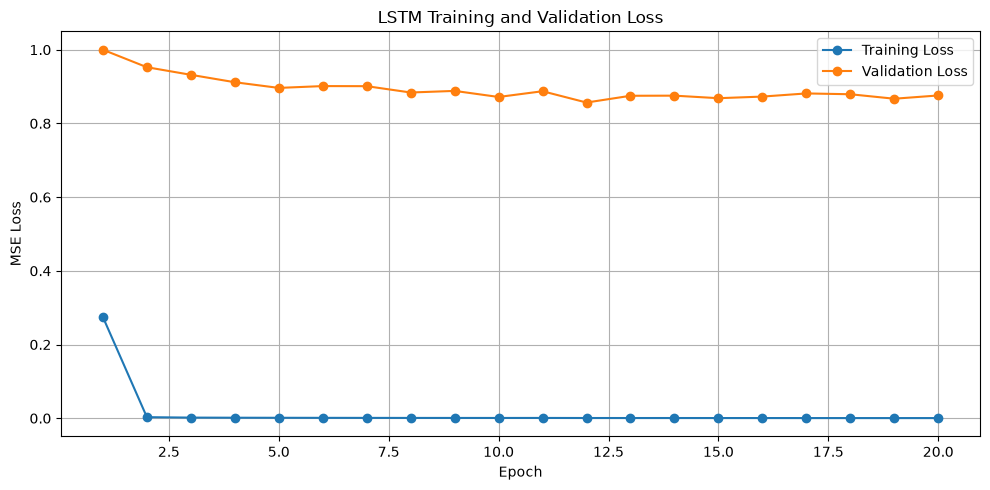

In [67]:
# Step 36: Load best model and visualize training history

import matplotlib.pyplot as plt
import torch

# Load our own trusted checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

# Restore best model
model.load_state_dict(checkpoint["model_state_dict"])

# Restore scalers from checkpoint
input_scaler = checkpoint["input_scaler"]
target_scaler = checkpoint["target_scaler"]

model.eval()

print("Best model loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss",
    marker="o"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [68]:
# Step 37: Diagnose train-validation distribution differences

import numpy as np
import pandas as pd

# 1. Compare original target coordinates
print("ORIGINAL TARGET COORDINATE DISTRIBUTION")

for split in ["Train", "Validation", "Test"]:

    coordinates = y_data[split].reshape(-1, 2)

    print(f"\n{split}")
    print("Latitude min/max:", coordinates[:, 0].min(),
          coordinates[:, 0].max())
    print("Longitude min/max:", coordinates[:, 1].min(),
          coordinates[:, 1].max())
    print("Latitude mean:", coordinates[:, 0].mean())
    print("Longitude mean:", coordinates[:, 1].mean())


# 2. Compare scaled target distributions
print("\nSCALED TARGET DISTRIBUTION")

for split in ["Train", "Validation", "Test"]:

    scaled = y_scaled[split].reshape(-1, 2)

    print(f"\n{split}")
    print("Mean:", scaled.mean(axis=0))
    print("Standard deviation:", scaled.std(axis=0))
    print("Minimum:", scaled.min(axis=0))
    print("Maximum:", scaled.max(axis=0))


# 3. Compare model against a simple persistence baseline
# Baseline: predict that the vessel remains at its last observed position.

last_positions = {}

for split in ["Train", "Validation", "Test"]:

    last_raw = X_data[split][:, -1, :2]

    last_scaled = target_scaler.transform(
        last_raw
    )

    baseline_predictions = np.repeat(
        last_scaled[:, np.newaxis, :],
        PREDICTION_LENGTH,
        axis=1
    )

    baseline_mse = np.mean(
        (baseline_predictions - y_scaled[split]) ** 2
    )

    last_positions[split] = baseline_mse

    print(f"\n{split} persistence baseline MSE: {baseline_mse:.6f}")


# 4. Calculate best model validation MSE
model.eval()

validation_predictions = []

with torch.no_grad():

    for X_batch, _ in val_loader:

        predictions = model(X_batch.to(device))

        validation_predictions.append(
            predictions.cpu().numpy()
        )

validation_predictions = np.concatenate(
    validation_predictions,
    axis=0
)

model_validation_mse = np.mean(
    (validation_predictions - y_scaled["Validation"]) ** 2
)

print("\nMODEL VS BASELINE")
print("LSTM validation MSE:", model_validation_mse)
print("Persistence baseline MSE:",
      last_positions["Validation"])

ORIGINAL TARGET COORDINATE DISTRIBUTION

Train
Latitude min/max: 54.44284 55.26218
Longitude min/max: 10.779813 14.090292
Latitude mean: 54.776184
Longitude mean: 12.035199

Validation
Latitude min/max: 55.274323 55.78673
Longitude min/max: 10.791163 11.068699
Latitude mean: 55.51907
Longitude mean: 10.905747

Test
Latitude min/max: 55.80155 56.259533
Longitude min/max: 10.804474 11.365912
Latitude mean: 56.0255
Longitude mean: 11.075697

SCALED TARGET DISTRIBUTION

Train
Mean: [-9.2123837e-06 -9.4867985e-08]
Standard deviation: [1.0000002 0.9999886]
Minimum: [-1.4869404 -1.2213058]
Maximum: [2.1678343 1.9993023]

Validation
Mean: [ 3.313719  -1.0987917]
Standard deviation: [0.6668823  0.09872662]
Minimum: [ 2.221996  -1.2102634]
Maximum: [ 4.507666   -0.94026226]

Test
Mean: [ 5.572746  -0.9334545]
Standard deviation: [0.5565287  0.16778168]
Minimum: [ 4.573773  -1.1973143]
Maximum: [ 6.616659  -0.6511173]

Train persistence baseline MSE: 0.000014

Validation persistence baseline MSE:

In [69]:
# Step 38: Evaluate LSTM vs Persistence Baseline

import numpy as np
import torch

def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371000  # Earth radius in metres

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(a))


for split in ["Validation", "Test"]:

    # Generate LSTM predictions
    loader = val_loader if split == "Validation" else test_loader

    model.eval()
    predictions = []

    with torch.no_grad():

        for X_batch, _ in loader:

            output = model(X_batch.to(device))
            predictions.append(output.cpu().numpy())

    predictions = np.concatenate(predictions, axis=0)

    # Convert scaled predictions into actual coordinates
    lstm_pred = target_scaler.inverse_transform(
        predictions.reshape(-1, 2)
    ).reshape(-1, PREDICTION_LENGTH, 2)

    # Actual future coordinates
    actual = y_data[split]

    # Persistence: repeat the last known input position
    last_position = X_data[split][:, -1, :2]

    baseline_pred = np.repeat(
        last_position[:, np.newaxis, :],
        PREDICTION_LENGTH,
        axis=1
    )

    # Calculate geographic errors
    lstm_errors = haversine_distance(
        actual[:, :, 0],
        actual[:, :, 1],
        lstm_pred[:, :, 0],
        lstm_pred[:, :, 1]
    )

    baseline_errors = haversine_distance(
        actual[:, :, 0],
        actual[:, :, 1],
        baseline_pred[:, :, 0],
        baseline_pred[:, :, 1]
    )

    print(f"\n{split.upper()} RESULTS")
    print("-" * 40)

    print("LSTM ADE:", round(lstm_errors.mean(), 2), "metres")
    print("LSTM FDE:", round(lstm_errors[:, -1].mean(), 2), "metres")

    print("Persistence ADE:", round(baseline_errors.mean(), 2), "metres")
    print("Persistence FDE:", round(baseline_errors[:, -1].mean(), 2), "metres")


VALIDATION RESULTS
----------------------------------------
LSTM ADE: 31376.48 metres
LSTM FDE: 31528.35 metres
Persistence ADE: 169.33 metres
Persistence FDE: 290.29 metres

TEST RESULTS
----------------------------------------
LSTM ADE: 84131.08 metres
LSTM FDE: 82993.7 metres
Persistence ADE: 179.73 metres
Persistence FDE: 308.11 metres


In [70]:
# Step 39: Inspect LSTM predicted coordinates

for split in ["Validation", "Test"]:

    loader = val_loader if split == "Validation" else test_loader

    model.eval()
    predictions = []

    with torch.no_grad():
        for X_batch, _ in loader:
            output = model(X_batch.to(device))
            predictions.append(output.cpu().numpy())

    predictions = np.concatenate(predictions, axis=0)

    # Convert predictions back to latitude and longitude
    predicted_coordinates = target_scaler.inverse_transform(
        predictions.reshape(-1, 2)
    ).reshape(-1, PREDICTION_LENGTH, 2)

    actual_coordinates = y_data[split]

    print(f"\n{split.upper()} COORDINATE DIAGNOSTICS")
    print("-" * 45)

    for i, coordinate in enumerate(["Latitude", "Longitude"]):

        print(f"\n{coordinate}")

        print("Actual mean:",
              round(actual_coordinates[:, :, i].mean(), 6))

        print("Predicted mean:",
              round(predicted_coordinates[:, :, i].mean(), 6))

        print("Actual range:",
              round(actual_coordinates[:, :, i].min(), 6),
              "to",
              round(actual_coordinates[:, :, i].max(), 6))

        print("Predicted range:",
              round(predicted_coordinates[:, :, i].min(), 6),
              "to",
              round(predicted_coordinates[:, :, i].max(), 6))

    # Show first five predicted positions
    print("\nFirst sample: actual vs predicted")

    comparison = pd.DataFrame({
        "Actual_Latitude": actual_coordinates[0, :, 0],
        "Predicted_Latitude": predicted_coordinates[0, :, 0],
        "Actual_Longitude": actual_coordinates[0, :, 1],
        "Predicted_Longitude": predicted_coordinates[0, :, 1]
    })

    display(comparison)


VALIDATION COORDINATE DIAGNOSTICS
---------------------------------------------

Latitude
Actual mean: 55.51907
Predicted mean: 55.26979
Actual range: 55.274323 to 55.78673
Predicted range: 55.249615 to 55.286568

Longitude
Actual mean: 10.905747
Predicted mean: 11.133932
Actual range: 10.791163 to 11.068699
Predicted range: 11.098253 to 11.180883

First sample: actual vs predicted


,Actual_Latitude,Predicted_Latitude,Actual_Longitude,Predicted_Longitude
0,55.274323,55.251740,11.068699,11.098949
1,55.274738,55.257034,11.068354,11.119296
2,55.275047,55.256474,11.068098,11.110875
3,55.275513,55.257793,11.067713,11.121304
4,55.275909,55.255440,11.067386,11.104846
5,55.276314,55.262390,11.067049,11.131467



TEST COORDINATE DIAGNOSTICS
---------------------------------------------

Latitude
Actual mean: 56.0255
Predicted mean: 55.276688
Actual range: 55.80155 to 56.259533
Predicted range: 55.265537 to 55.295433

Longitude
Actual mean: 11.075697
Predicted mean: 11.142069
Actual range: 10.804474 to 11.365912
Predicted range: 11.096905 to 11.193037

First sample: actual vs predicted


,Actual_Latitude,Predicted_Latitude,Actual_Longitude,Predicted_Longitude
0,55.801552,55.268566,10.804852,11.104637
1,55.802032,55.279709,10.804852,11.142105
2,55.802513,55.272621,10.804853,11.131247
3,55.802998,55.275742,10.804857,11.149799
4,55.803478,55.272221,10.804858,11.127060
5,55.803963,55.287064,10.804860,11.165259


In [71]:
# Step 40: Constant Velocity Baseline

def constant_velocity_prediction(X, prediction_length=6):

    # Last two observed positions
    previous = X[:, -2, :2]
    last = X[:, -1, :2]

    # Movement per 10-second interval
    movement = last - previous

    predictions = []

    for step in range(1, prediction_length + 1):

        future_position = last + (movement * step)

        predictions.append(future_position)

    return np.stack(predictions, axis=1)


# Evaluate on validation and test data

for split in ["Validation", "Test"]:

    # Actual future coordinates
    actual = y_data[split]

    # Generate predictions
    cv_predictions = constant_velocity_prediction(
        X_data[split],
        PREDICTION_LENGTH
    )

    # Calculate geographic errors
    cv_errors = haversine_distance(
        actual[:, :, 0],
        actual[:, :, 1],
        cv_predictions[:, :, 0],
        cv_predictions[:, :, 1]
    )

    print(f"\n{split.upper()} CONSTANT VELOCITY RESULTS")
    print("-" * 45)

    print("ADE:", round(cv_errors.mean(), 2), "metres")

    print(
        "FDE:",
        round(cv_errors[:, -1].mean(), 2),
        "metres"
    )


VALIDATION CONSTANT VELOCITY RESULTS
---------------------------------------------
ADE: 8.91 metres
FDE: 14.55 metres

TEST CONSTANT VELOCITY RESULTS
---------------------------------------------
ADE: 9.42 metres
FDE: 15.6 metres


In [72]:
# Step 41: Analyze original and interpolated observations

print("OBSERVATION TYPE DISTRIBUTION")
print("=" * 50)

for split in ["Train", "Validation", "Test"]:

    split_df = valid_df[valid_df["Split"] == split]

    print(f"\n{split.upper()}")

    counts = split_df["Data_Type"].value_counts()

    percentages = (
        split_df["Data_Type"]
        .value_counts(normalize=True) * 100
    )

    distribution = pd.DataFrame({
        "Number_of_Records": counts,
        "Percentage": percentages.round(2)
    })

    display(distribution)

print("\nOVERALL DISTRIBUTION")

display(
    valid_df["Data_Type"]
    .value_counts()
    .to_frame("Number_of_Records")
)

OBSERVATION TYPE DISTRIBUTION

TRAIN


,Number_of_Records,Percentage
Data_Type,,
Interpolated,5472,90.87
Original,550,9.13



VALIDATION


,Number_of_Records,Percentage
Data_Type,,
Interpolated,1056,81.86
Original,234,18.14



TEST


,Number_of_Records,Percentage
Data_Type,,
Interpolated,920,71.26
Original,371,28.74



OVERALL DISTRIBUTION


,Number_of_Records
Data_Type,
Interpolated,7448
Original,1155


In [73]:
# Step 42: Count original AIS observations in test targets

original_target_counts = []

for (split, segment_id), group in valid_df.groupby(
    ["Split", "Segment_ID"]
):

    if split != "Test":
        continue

    group = group.sort_values("# Timestamp").reset_index(drop=True)

    if len(group) < SEQUENCE_LENGTH + PREDICTION_LENGTH:
        continue

    data_types = group["Data_Type"].to_numpy()

    for i in range(
        len(group) - SEQUENCE_LENGTH - PREDICTION_LENGTH + 1
    ):

        future_types = data_types[
            i + SEQUENCE_LENGTH:
            i + SEQUENCE_LENGTH + PREDICTION_LENGTH
        ]

        original_target_counts.append(
            np.sum(future_types == "Original")
        )

original_target_counts = np.array(original_target_counts)

print("TEST TARGET OBSERVATION ANALYSIS")
print("--------------------------------")

print("Total test sequences:", len(original_target_counts))

print(
    "Sequences with at least one original future observation:",
    np.sum(original_target_counts > 0)
)

print(
    "Sequences with all 6 original future observations:",
    np.sum(original_target_counts == PREDICTION_LENGTH)
)

print(
    "Sequences with no original future observations:",
    np.sum(original_target_counts == 0)
)

print(
    "Total original future target points:",
    original_target_counts.sum()
)

print(
    "Total possible future target points:",
    len(original_target_counts) * PREDICTION_LENGTH
)

print(
    "Percentage of original future target points:",
    round(
        original_target_counts.sum()
        / (len(original_target_counts) * PREDICTION_LENGTH) * 100,
        2
    ),
    "%"
)

TEST TARGET OBSERVATION ANALYSIS
--------------------------------
Total test sequences: 1256
Sequences with at least one original future observation: 821
Sequences with all 6 original future observations: 86
Sequences with no original future observations: 435
Total original future target points: 2199
Total possible future target points: 7536
Percentage of original future target points: 29.18 %


In [74]:
# Step 43: Recreate metadata for test sequences

test_target_types = []

for (split, segment_id), group in valid_df.groupby(
    ["Split", "Segment_ID"]
):
    if split != "Test":
        continue

    group = group.sort_values("# Timestamp").reset_index(drop=True)

    if len(group) < SEQUENCE_LENGTH + PREDICTION_LENGTH:
        continue

    data_types = group["Data_Type"].to_numpy()

    for i in range(
        len(group) - SEQUENCE_LENGTH - PREDICTION_LENGTH + 1
    ):
        future_types = data_types[
            i + SEQUENCE_LENGTH:
            i + SEQUENCE_LENGTH + PREDICTION_LENGTH
        ]

        test_target_types.append(future_types)

test_target_types = np.array(test_target_types)

print("Test target metadata shape:", test_target_types.shape)
print("Matches test target array:", 
      test_target_types.shape[0] == len(y_data["Test"]))
print("Original target points:",
      np.sum(test_target_types == "Original"))
print("Interpolated target points:",
      np.sum(test_target_types == "Interpolated"))

Test target metadata shape: (1256, 6)
Matches test target array: True
Original target points: 2199
Interpolated target points: 5337


In [75]:
# Step 44: Evaluate models only on original AIS target positions

def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371000  # Earth radius in metres

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(a))


# Restore best LSTM model
checkpoint = torch.load(
    "../models/best_lstm_baseline.pt",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Generate LSTM predictions
with torch.no_grad():
    lstm_scaled = model(X_test_tensor).cpu().numpy()

# Convert LSTM predictions back to latitude/longitude
lstm_predictions = target_scaler.inverse_transform(
    lstm_scaled.reshape(-1, 2)
).reshape(-1, PREDICTION_LENGTH, 2)

# Convert actual targets back to latitude/longitude
actual_positions = target_scaler.inverse_transform(
    y_scaled["Test"].reshape(-1, 2)
).reshape(-1, PREDICTION_LENGTH, 2)

# Generate constant-velocity predictions
cv_scaled = constant_velocity_prediction(
    X_scaled["Test"],
    PREDICTION_LENGTH
)

cv_predictions = target_scaler.inverse_transform(
    cv_scaled.reshape(-1, 2)
).reshape(-1, PREDICTION_LENGTH, 2)

# Mask for actual AIS observations
original_mask = test_target_types == "Original"

# Calculate geographic errors
lstm_errors = haversine_distance(
    actual_positions[:, :, 0],
    actual_positions[:, :, 1],
    lstm_predictions[:, :, 0],
    lstm_predictions[:, :, 1]
)

cv_errors = haversine_distance(
    actual_positions[:, :, 0],
    actual_positions[:, :, 1],
    cv_predictions[:, :, 0],
    cv_predictions[:, :, 1]
)

# Evaluate only original AIS targets
lstm_original_errors = lstm_errors[original_mask]
cv_original_errors = cv_errors[original_mask]

print("ORIGINAL AIS TARGET EVALUATION")
print("--------------------------------")
print("Original target points:", original_mask.sum())

print("\nLSTM:")
print("ADE (metres):", round(lstm_original_errors.mean(), 2))
print("Median error (metres):", round(np.median(lstm_original_errors), 2))
print("Maximum error (metres):", round(lstm_original_errors.max(), 2))

print("\nCONSTANT VELOCITY:")
print("ADE (metres):", round(cv_original_errors.mean(), 2))
print("Median error (metres):", round(np.median(cv_original_errors), 2))
print("Maximum error (metres):", round(cv_original_errors.max(), 2))

ORIGINAL AIS TARGET EVALUATION
--------------------------------
Original target points: 2199

LSTM:
ADE (metres): 93924.05
Median error (metres): 96251.53
Maximum error (metres): 110178.41

CONSTANT VELOCITY:
ADE (metres): 687.37
Median error (metres): 699.64
Maximum error (metres): 850.2


In [76]:
# Step 45: Analyze actual vessel movement in test period

test_actual = actual_positions.reshape(-1, 2)

test_lat_min = test_actual[:, 0].min()
test_lat_max = test_actual[:, 0].max()

test_lon_min = test_actual[:, 1].min()
test_lon_max = test_actual[:, 1].max()

print("TEST PERIOD GEOGRAPHIC MOVEMENT")
print("--------------------------------")
print("Latitude range:", test_lat_min, "to", test_lat_max)
print("Longitude range:", test_lon_min, "to", test_lon_max)

print("\nFirst actual test position:")
print(actual_positions[0, 0])

print("\nLast actual test position:")
print(actual_positions[-1, -1])

print("\nFirst LSTM prediction:")
print(lstm_predictions[0, 0])

print("\nFirst constant velocity prediction:")
print(cv_predictions[0, 0])

TEST PERIOD GEOGRAPHIC MOVEMENT
--------------------------------
Latitude range: 55.80155 to 56.259533
Longitude range: 10.804474 to 11.365912

First actual test position:
[55.80155  10.804852]

Last actual test position:
[56.259533 11.365912]

First LSTM prediction:
[55.268566 11.104637]

First constant velocity prediction:
[55.80594  10.801805]


In [77]:
# Step 46: Compare geographic distribution across splits

for split_name in ["Train", "Validation", "Test"]:

    split_data = valid_df[valid_df["Split"] == split_name]

    print(f"\n{split_name.upper()} PERIOD")
    print("-" * 35)

    print("Records:", len(split_data))

    print(
        "Latitude:",
        round(split_data["Latitude"].min(), 6),
        "to",
        round(split_data["Latitude"].max(), 6)
    )

    print(
        "Longitude:",
        round(split_data["Longitude"].min(), 6),
        "to",
        round(split_data["Longitude"].max(), 6)
    )

    print(
        "Mean latitude:",
        round(split_data["Latitude"].mean(), 6)
    )

    print(
        "Mean longitude:",
        round(split_data["Longitude"].mean(), 6)
    )


TRAIN PERIOD
-----------------------------------
Records: 6022
Latitude: 54.442447 to 55.262179
Longitude: 10.779813 to 14.106402
Mean latitude: 54.769141
Mean longitude: 12.053489

VALIDATION PERIOD
-----------------------------------
Records: 1290
Latitude: 55.262561 to 55.786731
Longitude: 10.791163 to 11.077835
Mean latitude: 55.512657
Mean longitude: 10.908926

TEST PERIOD
-----------------------------------
Records: 1291
Latitude: 55.787207 to 56.259533
Longitude: 10.804474 to 11.365912
Mean latitude: 56.020143
Mean longitude: 11.069438


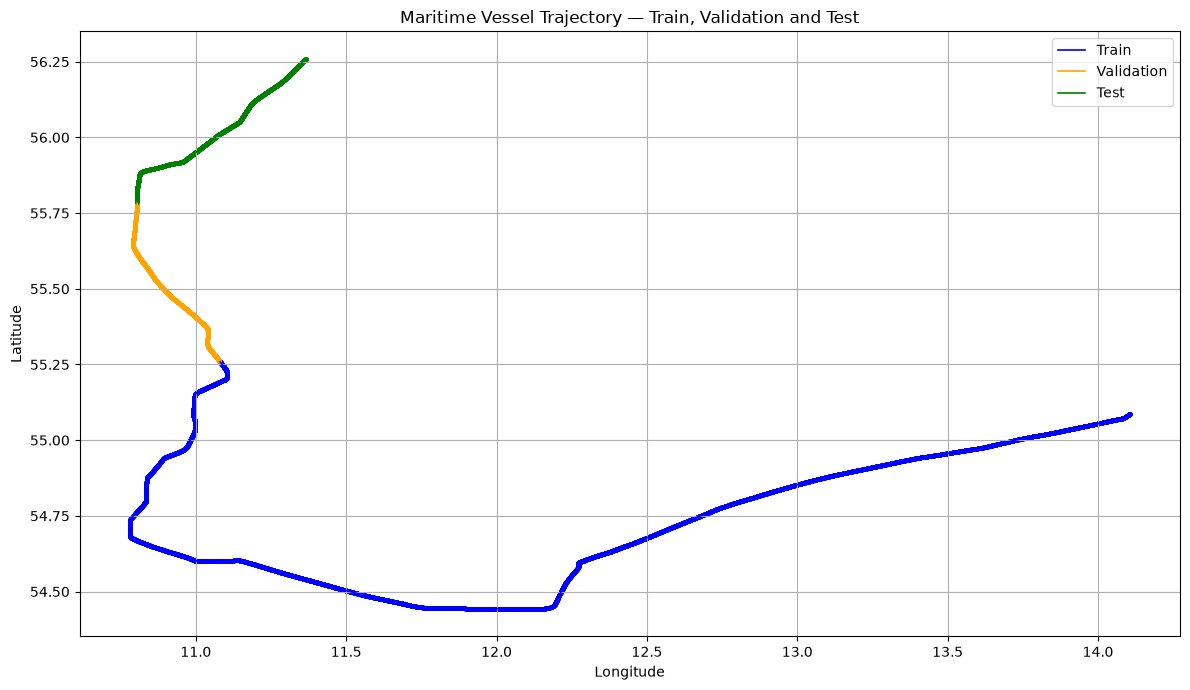

In [78]:
# Step 47: Plot geographic trajectory by data split

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

split_colors = {
    "Train": "blue",
    "Validation": "orange",
    "Test": "green"
}

for split_name, color in split_colors.items():

    split_data = valid_df[
        valid_df["Split"] == split_name
    ].sort_values("# Timestamp")

    plt.plot(
        split_data["Longitude"],
        split_data["Latitude"],
        color=color,
        label=split_name,
        linewidth=1.2
    )

    plt.scatter(
        split_data["Longitude"],
        split_data["Latitude"],
        color=color,
        s=5
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Maritime Vessel Trajectory — Train, Validation and Test")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [79]:
# Step 48: Constant velocity error at each prediction horizon

print("CONSTANT VELOCITY — ERROR BY PREDICTION HORIZON")
print("-" * 55)

for step in range(PREDICTION_LENGTH):

    step_mask = test_target_types[:, step] == "Original"

    step_errors = cv_errors[:, step][step_mask]

    if len(step_errors) > 0:
        print(
            f"Step {step + 1} "
            f"({(step + 1) * 10} seconds): "
            f"{len(step_errors)} original points | "
            f"Mean error: {step_errors.mean():.2f} m | "
            f"Median error: {np.median(step_errors):.2f} m"
        )
    else:
        print(f"Step {step + 1}: No original observations")

CONSTANT VELOCITY — ERROR BY PREDICTION HORIZON
-------------------------------------------------------
Step 1 (10 seconds): 364 original points | Mean error: 686.62 m | Median error: 697.85 m
Step 2 (20 seconds): 365 original points | Mean error: 686.86 m | Median error: 698.74 m
Step 3 (30 seconds): 366 original points | Mean error: 687.59 m | Median error: 700.59 m
Step 4 (40 seconds): 367 original points | Mean error: 687.29 m | Median error: 694.50 m
Step 5 (50 seconds): 368 original points | Mean error: 685.65 m | Median error: 700.79 m
Step 6 (60 seconds): 369 original points | Mean error: 690.19 m | Median error: 701.51 m


In [80]:
# Step 49: Recalculate constant velocity using raw coordinates

# Use original, unscaled test input sequences
cv_raw_predictions = constant_velocity_prediction(
    X_data["Test"],
    PREDICTION_LENGTH
)

# Actual future coordinates are also unscaled
actual_raw = y_data["Test"]

# Calculate geographic errors
cv_raw_errors = haversine_distance(
    actual_raw[:, :, 0],
    actual_raw[:, :, 1],
    cv_raw_predictions[:, :, 0],
    cv_raw_predictions[:, :, 1]
)

# Evaluate only original AIS target points
cv_raw_original_errors = cv_raw_errors[original_mask]

print("CORRECTED CONSTANT VELOCITY EVALUATION")
print("--------------------------------------")
print("Original AIS target points:", len(cv_raw_original_errors))
print("ADE (metres):", round(cv_raw_original_errors.mean(), 2))
print("Median error (metres):", round(np.median(cv_raw_original_errors), 2))
print("Maximum error (metres):", round(cv_raw_original_errors.max(), 2))

print("\nERROR BY PREDICTION HORIZON")
for step in range(PREDICTION_LENGTH):
    mask = original_mask[:, step]
    errors = cv_raw_errors[:, step][mask]

    print(
        f"{(step + 1) * 10} seconds: "
        f"{errors.mean():.2f} m "
        f"({len(errors)} original points)"
    )

CORRECTED CONSTANT VELOCITY EVALUATION
--------------------------------------
Original AIS target points: 2199
ADE (metres): 9.26
Median error (metres): 3.53
Maximum error (metres): 246.42

ERROR BY PREDICTION HORIZON
10 seconds: 3.77 m (364 original points)
20 seconds: 5.60 m (365 original points)
30 seconds: 8.58 m (366 original points)
40 seconds: 10.54 m (367 original points)
50 seconds: 12.26 m (368 original points)
60 seconds: 14.72 m (369 original points)


In [81]:
# Step 50: Save processed project checkpoint

from pathlib import Path
import joblib

# Create checkpoint folder
checkpoint_dir = Path("../data/processed")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Collect important project variables
project_checkpoint = {
    "trajectory_df": trajectory_df,
    "resampled_df": resampled_df,
    "model_df": model_df,
    "valid_df": valid_df,

    "X_data": X_data,
    "y_data": y_data,
    "X_scaled": X_scaled,
    "y_scaled": y_scaled,

    "input_scaler": input_scaler,
    "target_scaler": target_scaler,

    "test_target_types": test_target_types,

    "SEQUENCE_LENGTH": SEQUENCE_LENGTH,
    "PREDICTION_LENGTH": PREDICTION_LENGTH
}

# Save everything
checkpoint_path = checkpoint_dir / "trajectory_checkpoint.joblib"

joblib.dump(project_checkpoint, checkpoint_path, compress=3)

print("PROJECT CHECKPOINT SAVED SUCCESSFULLY")
print("--------------------------------------")
print("Location:", checkpoint_path.resolve())
print("File size (MB):", round(checkpoint_path.stat().st_size / (1024 * 1024), 2))
print("Saved variables:", len(project_checkpoint))

PROJECT CHECKPOINT SAVED SUCCESSFULLY
--------------------------------------
Location: D:\Meritime_Trajectory\data\processed\trajectory_checkpoint.joblib
File size (MB): 1.52
Saved variables: 13


In [84]:
# Step 52: Save corrected evaluation results

evaluation_results = {
    "cv_raw_predictions": cv_raw_predictions,
    "cv_raw_errors": cv_raw_errors,
    "cv_raw_original_errors": cv_raw_original_errors,
    "lstm_predictions": lstm_predictions,
    "actual_positions": actual_positions,
    "original_mask": original_mask
}

evaluation_path = Path("../data/processed/evaluation_results.joblib")

joblib.dump(evaluation_results, evaluation_path, compress=3)

print("Evaluation results saved!")
print("Location:", evaluation_path.resolve())

Evaluation results saved!
Location: D:\Meritime_Trajectory\data\processed\evaluation_results.joblib
